# ¿Hay señales de condiciones más secas durante la época cálida en La Araucanía?
## Humedad del suelo, tendencias ambientales y contexto de incendios · 2014–2023

**Pregunta principal:** ¿disminuye la humedad superficial del suelo durante noviembre–marzo? ¿Es un patrón regional, territorialmente consistente y acompañado por cambios en humedad relativa, precipitación o temperatura?

Se usan exclusivamente los CSV limpios disponibles. Se analiza primero el cambio ambiental en **120 meses**, sin recortarlo a CONAF. El cruce de incendios es un contraste descriptivo posterior y no determina si existe tendencia. No se descargan observaciones, no se modifican CSV y no se exportan resultados fuera de este notebook.

**Hipótesis primaria predefinida:** pendiente negativa de `soil_moisture_0_10cm_kgm2` en noviembre–marzo. Se informan pruebas bilaterales e intervalos, sin buscar solo resultados de signo favorable. La ventana cálida se fija antes de las pruebas; no es una estación oficial de incendios.

In [3]:
%matplotlib inline
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 22)
pd.set_option('display.max_rows', 45)
pd.set_option('display.float_format',lambda x:f'{x:.4f}')
RAIZ=next(q for q in [Path.cwd(),*Path.cwd().parents] if (q/'datos_mensuales_2014_2023/limpios').is_dir() or (q/'DeHecho/datos_mensuales_2014_2023/limpios').is_dir())
if not (RAIZ/'datos_mensuales_2014_2023/limpios').is_dir():RAIZ=RAIZ/'DeHecho'
BASE=RAIZ/'datos_mensuales_2014_2023/limpios'
ARCHIVOS=[BASE/'region_mensual_limpio.csv',BASE/'comunas_mensual_limpio.csv',BASE/'reporte_validacion.json',RAIZ/'data/conaf/conaf.csv']
hashes_inicio={str(f):hashlib.sha256(f.read_bytes()).hexdigest() for f in ARCHIVOS}
regional=pd.read_csv(ARCHIVOS[0],dtype={'region_id':'string'})
comunal=pd.read_csv(ARCHIVOS[1],dtype={'region_id':'string','commune_id':'string'})
reporte=json.loads(ARCHIVOS[2].read_text(encoding='utf-8-sig'))
SUELO='soil_moisture_0_10cm_kgm2'
VARS=[SUELO,'relative_humidity_2m_pct','precipitation_mm','temperature_2m_c']
NOMBRES={SUELO:'Agua del suelo (0–10 cm)','relative_humidity_2m_pct':'Humedad relativa a 2 m','precipitation_mm':'Precipitación mensual','temperature_2m_c':'Temperatura del aire a 2 m'}
UNIDADES={SUELO:'kg/m²','relative_humidity_2m_pct':'puntos porcentuales','precipitation_mm':'mm/mes','temperature_2m_c':'°C'}
UMBRAL=float(reporte['soil_coverage_threshold_pct'])
CALIDOS=[11,12,1,2,3]
for d in [regional,comunal]:
    d['fecha']=pd.to_datetime(d.month,format='%Y-%m')
    d['mes']=d.fecha.dt.month
    d['anio']=d.fecha.dt.year
    d['indice_mes']=(d.anio-2014)*12+d.mes-1
    if d.soil_coverage_ok.dtype!=bool:
        d['soil_coverage_ok']=d.soil_coverage_ok.astype(str).str.lower().map({'true':True,'false':False})
    assert d.soil_coverage_ok.notna().all()
    assert d.soil_coverage_ok.eq(d.suelo_mensual_valid_area_pct.ge(UMBRAL)).all()
    # Aplicar la bandera existente sin rehacer la limpieza ni eliminar incendios.
    d.loc[~d.soil_coverage_ok,SUELO]=np.nan
regional=regional.sort_values('fecha').reset_index(drop=True)
comunal=comunal.sort_values(['commune_id','fecha']).reset_index(drop=True)
assert len(regional)==120 and not regional.fecha.duplicated().any()
assert len(comunal)==3840 and not comunal.duplicated(['commune_id','fecha']).any()
assert regional.indice_mes.tolist()==list(range(120))
assert comunal.groupby('commune_id').indice_mes.apply(lambda x:x.tolist()==list(range(120))).all()
print('Python:',platform.python_version(),'| pandas:',pd.__version__)
print('Cobertura mínima de suelo:',UMBRAL,'% | período:',regional.month.min(),'a',regional.month.max())
display(comunal.groupby('commune_name').agg(meses=('fecha','size'),suelo_valido=(SUELO,'count'),cobertura_minima=('suelo_mensual_valid_area_pct','min')).sort_values('cobertura_minima').head(8))

Python: 3.14.8 | pandas: 3.0.6
Cobertura mínima de suelo: 80.0 % | período: 2014-01 a 2023-12


,meses,suelo_valido,cobertura_minima
commune_name,,,
Saavedra,120,0,36.4900
Teodoro Schmidt,120,120,84.5800
Carahue,120,120,99.0600
Angol,120,120,100.0000
Cunco,120,120,100.0000
Curacautín,120,120,100.0000
Cholchol,120,120,100.0000
Collipulli,120,120,100.0000


## 1. Qué mide el análisis y qué queda excluido

El suelo expresa **masa de agua por superficie en los primeros 10 cm (kg/m²)**, no porcentaje de humedad ni humedad de combustible vegetal. Se respeta el umbral de **80 %** del reporte: Saavedra no tiene suelo utilizable, pero conserva sus otras variables y conteos. La sensibilidad al 90 % se evalúa separadamente, sin cambiar la regla principal.

La serie regional proviene del CSV regional; no se reemplaza por una media simple de comunas. Las comunas comparten píxeles del producto original: no son réplicas independientes. El período describe cambios entre 2014 y 2023, no atribución de cambio climático ni una tendencia de varias décadas.

## 2. Diseño estadístico fijado antes de las pruebas

Se ajusta `y = intercepto específico del mes + pendiente × tiempo` para la tendencia anual. Para comparar ventanas, se ajustan **dos pendientes simultáneas**, noviembre–marzo y abril–octubre, manteniendo interceptos mensuales. El tiempo conserva su escala calendario, en años. La pendiente cálida se apoya en 50 observaciones repartidas en diez años; no se finge que esos meses son consecutivos.

Los intervalos del 95 % y p-valores bilaterales utilizan covarianza **Newey–West/HAC**, pesos de Bartlett, rezago principal **12 meses** y corrección n/(n−k). Se usa una referencia t con n−k grados de libertad como aproximación, no una prueba exacta con muestra pequeña. Los rezagos se calculan por distancia calendario, incluso si se excluye un año. Referencia del estimador: [documentación HAC](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html).

**Multiplicidad:** se reporta la prueba primaria regional de suelo cálido tal como se predefinió y, adicionalmente, p ajustados Holm para las 12 combinaciones regionales (4 variables × 3 ventanas). Las pruebas comunales válidas forman otra familia conjunta; se aplica FDR Benjamini–Yekutieli (BY), que admite dependencia entre pruebas. Los intervalos mostrados son individuales, no simultáneos. [Referencia de correcciones](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html).

No se usa Mann–Kendall convencional sobre meses estacionales como sustituto de esta corrección temporal. HAC aproxima la incertidumbre bajo dependencia de corto alcance: no garantiza robustez frente a cualquier dependencia de largo plazo.

In [4]:
# OLS + covarianza Newey–West: implementación explícita, sin instalar paquetes.
def ajuste_hac(g,variable,diseno='anual',lag=12):
    a=g.loc[g[variable].notna()].sort_values('indice_mes').copy()
    ventanas=['anual'] if diseno=='anual' else ['nov_mar','abr_oct']
    salida=[]
    if len(a)<60 or a.anio.nunique()<8:
        return [dict(ventana=w,n=0 if a.empty else len(a),estado='datos insuficientes') for w in ventanas]
    meses=a.mes.to_numpy()
    idx=a.indice_mes.to_numpy(dtype=int)
    tiempo=idx/12-4.958333333333333
    interceptos=np.column_stack([(meses==m).astype(float) for m in range(1,13)])
    masks=[np.ones(len(a),bool)] if diseno=='anual' else [np.isin(meses,CALIDOS),~np.isin(meses,CALIDOS)]
    X=np.column_stack([interceptos]+[tiempo*m for m in masks])
    y=a[variable].to_numpy(float)
    n,k=X.shape
    assert np.linalg.matrix_rank(X)==k
    beta=np.linalg.lstsq(X,y,rcond=None)[0]
    resid=y-X@beta
    bread=np.linalg.inv(X.T@X)
    z=X*resid[:,None]
    meat=z.T@z
    # La distancia entre filas NO sustituye a la distancia calendario.
    posicion={int(m):i for i,m in enumerate(idx)}
    for h in range(1,lag+1):
        pares=[(i,posicion[int(m-h)]) for i,m in enumerate(idx) if int(m-h) in posicion]
        if pares:
            ii,jj=np.asarray(pares).T
            gamma=z[ii].T@z[jj]
            meat+=(1-h/(lag+1))*(gamma+gamma.T)
    cov=(n/(n-k))*bread@meat@bread
    cov=(cov+cov.T)/2
    assert np.linalg.eigvalsh(cov).min()>-1e-7
    crit=stats.t.ppf(.975,n-k)
    for j,(w,mask) in enumerate(zip(ventanas,masks)):
        b=float(beta[12+j]);se=float(np.sqrt(max(cov[12+j,12+j],0)))
        pval=2*stats.t.sf(abs(b/se),n-k) if se>0 else np.nan
        salida.append(dict(ventana=w,n=int(mask.sum()),n_modelo=n,anios=int(a.loc[mask,'anio'].nunique()),
          pendiente_anual=b,error_hac=se,ic95_inf=b-crit*se,ic95_sup=b+crit*se,p=float(pval),
          cambio_estimado_9anios=9*b,acf1_residuo=pd.Series(resid,index=idx).reindex(range(idx.min(),idx.max()+1)).autocorr(1),
          estado='estimado',lag_hac=lag))
    return salida

def corregir_p(p,metodo):
    p=np.asarray(p,float);m=len(p)
    if m==0:return p
    orden=np.argsort(p);s=p[orden]
    if metodo=='holm':adj=np.minimum(1,np.maximum.accumulate(s*(m-np.arange(m))))
    elif metodo=='by':
        c_m=np.sum(1/np.arange(1,m+1))
        adj=np.minimum(1,np.minimum.accumulate((s*m*c_m/np.arange(1,m+1))[::-1])[::-1])
    else:raise ValueError(metodo)
    out=np.empty(m);out[orden]=adj
    return out

# Comprobaciones matemáticas básicas de las funciones que sustentan la inferencia.
assert np.allclose(corregir_p([.01,.04,.03],'holm'),[.03,.06,.06])
assert np.all(corregir_p([.01,.04,.03],'by')>=np.array([.01,.04,.03]))
sintetico=regional[['mes','anio','indice_mes']].copy()
sintetico['y']=2*sintetico.indice_mes/12+np.sin(sintetico.mes)
assert abs(ajuste_hac(sintetico,'y')[0]['pendiente_anual']-2)<1e-9
print('Funciones verificadas: pendiente conocida y correcciones de multiplicidad.')

Funciones verificadas: pendiente conocida y correcciones de multiplicidad.


## 3. Tendencias regionales: ¿disminuye el agua del suelo?
Las pendientes cálida y fría proceden de un mismo modelo con interacción, no de concatenar artificialmente meses distantes. La pendiente anual procede de un modelo separado. Para precipitación, la pendiente tiene unidades de **mm de acumulado mensual por año**; no equivale al cambio en precipitación anual acumulada.

In [5]:
registros=[]
for variable in VARS:
    for modelo in ['anual','ventanas']:
        for r in ajuste_hac(regional,variable,modelo):
            registros.append(dict(variable=variable,unidad_por_anio=UNIDADES[variable]+'/año',**r))
tendencias_region=pd.DataFrame(registros)
tendencias_region['p_holm_regional']=corregir_p(tendencias_region.p,'holm')
tendencias_region['evidencia_holm']=tendencias_region.p_holm_regional.lt(.05)
display(tendencias_region[['variable','ventana','n','pendiente_anual','ic95_inf','ic95_sup','p','p_holm_regional','cambio_estimado_9anios','unidad_por_anio']])
primaria=tendencias_region[(tendencias_region.variable==SUELO)&(tendencias_region.ventana=='nov_mar')].iloc[0]
print('Prueba primaria predefinida: agua del suelo en noviembre–marzo.')
print(f'Pendiente {primaria.pendiente_anual:.4f} kg/m²/año; IC95% [{primaria.ic95_inf:.4f}, {primaria.ic95_sup:.4f}]; p={primaria.p:.4f}; p Holm={primaria.p_holm_regional:.4f}')

,variable,ventana,n,pendiente_anual,ic95_inf,ic95_sup,p,p_holm_regional,cambio_estimado_9anios,unidad_por_anio
0,soil_moisture_0_10cm_kgm2,anual,120,-0.1478,-0.3079,0.0122,0.0699,0.4434,-1.3303,kg/m²/año
1,soil_moisture_0_10cm_kgm2,nov_mar,50,-0.1822,-0.3748,0.0103,0.0633,0.4434,-1.6401,kg/m²/año
2,soil_moisture_0_10cm_kgm2,abr_oct,70,-0.1232,-0.3532,0.1068,0.2905,0.8715,-1.1090,kg/m²/año
3,relative_humidity_2m_pct,anual,120,-0.9343,-1.2890,-0.5797,0.0000,0.0000,-8.4089,puntos porcentuales/año
4,relative_humidity_2m_pct,nov_mar,50,-1.2543,-1.9196,-0.5890,0.0003,0.0030,-11.2887,puntos porcentuales/año
5,relative_humidity_2m_pct,abr_oct,70,-0.7058,-0.9290,-0.4825,0.0000,0.0000,-6.3519,puntos porcentuales/año
6,precipitation_mm,anual,120,-3.7091,-7.2433,-0.1749,0.0399,0.3189,-33.3819,mm/mes/año
7,precipitation_mm,nov_mar,50,-1.5229,-4.7244,1.6786,0.3478,0.8715,-13.7060,mm/mes/año
8,precipitation_mm,abr_oct,70,-5.2707,-11.2101,0.6687,0.0814,0.4434,-47.4360,mm/mes/año
9,temperature_2m_c,anual,120,0.0652,-0.0081,0.1385,0.0807,0.4434,0.5868,°C/año


Prueba primaria predefinida: agua del suelo en noviembre–marzo.
Pendiente -0.1822 kg/m²/año; IC95% [-0.3748, 0.0103]; p=0.0633; p Holm=0.4434


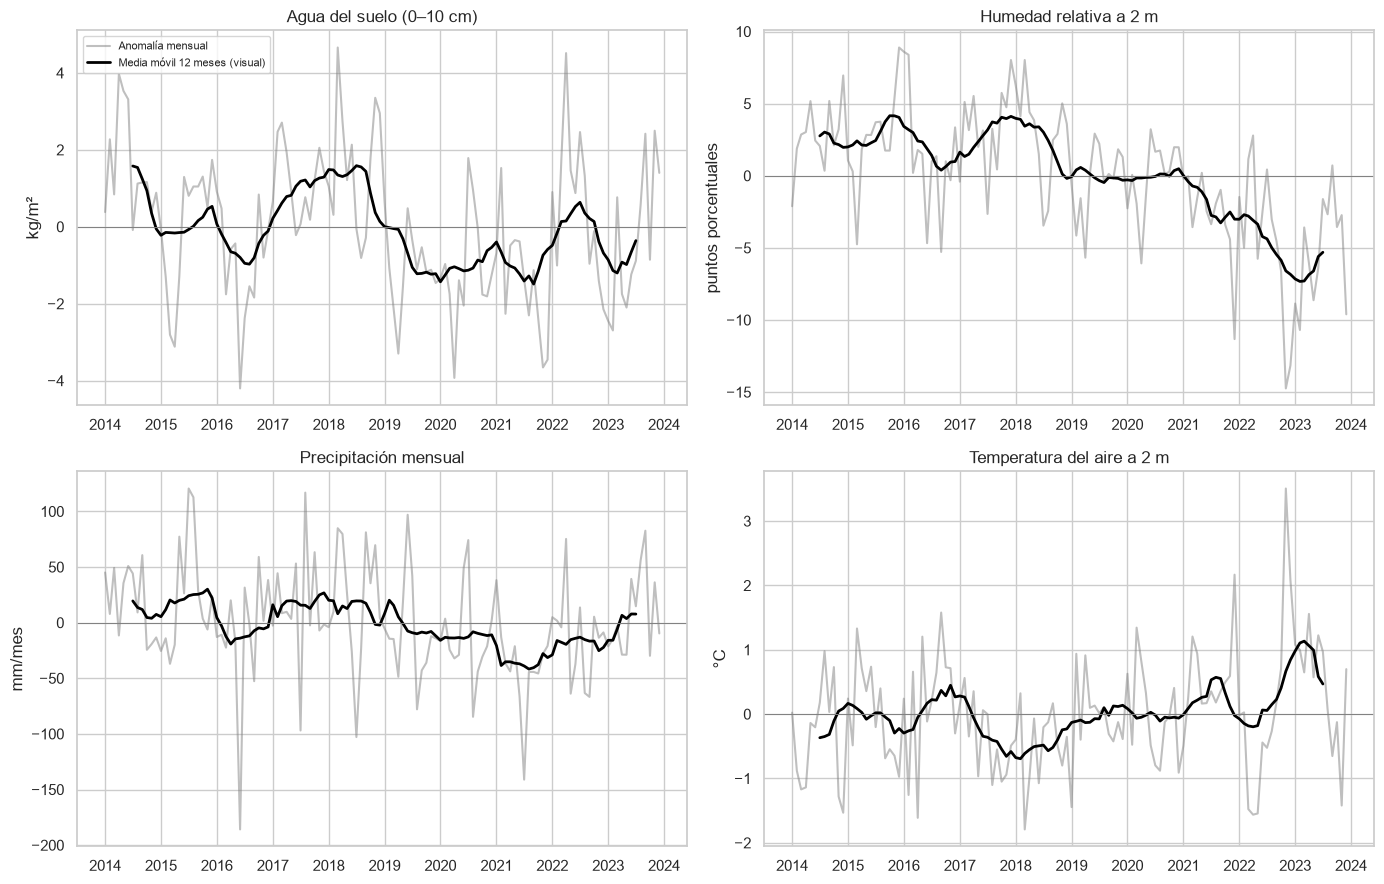

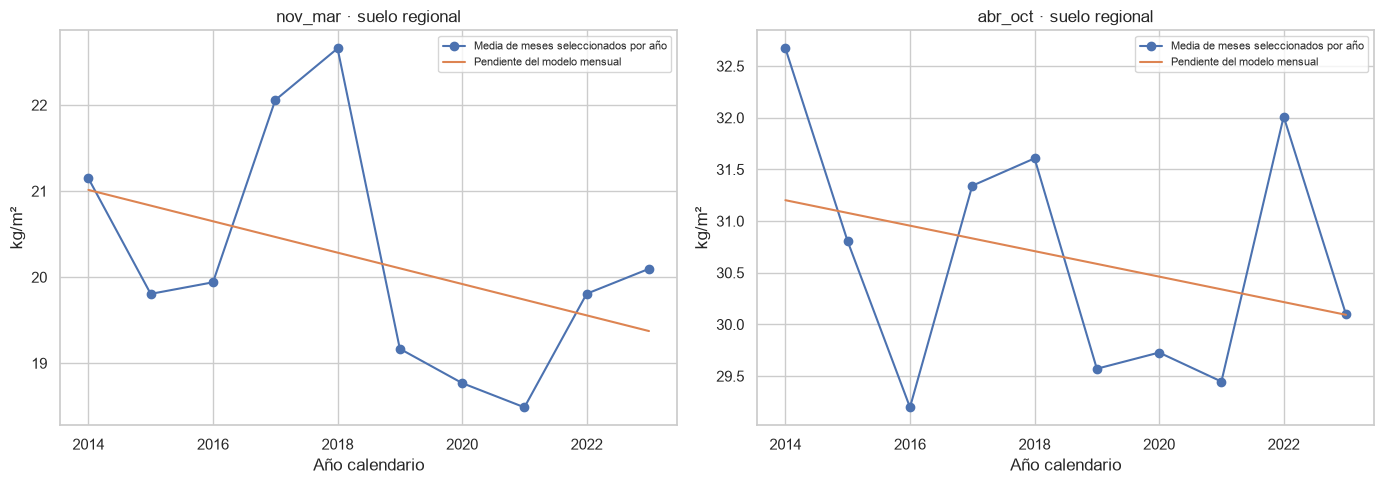

Noviembre–marzo agrupado por año calendario no representa una temporada cálida continua; esta figura es descriptiva.


In [6]:
# Anomalías para visualizar; la inferencia anterior ajusta ciclo y tendencia conjuntamente.
fig,axs=plt.subplots(2,2,figsize=(14,9))
for ax,v in zip(axs.flat,VARS):
    anom=regional[v]-regional.groupby('mes')[v].transform('mean')
    ax.plot(regional.fecha,anom,color='gray',alpha=.5,label='Anomalía mensual')
    ax.plot(regional.fecha,anom.rolling(12,center=True,min_periods=12).mean(),color='black',lw=2,label='Media móvil 12 meses (visual)')
    ax.axhline(0,color='gray',lw=.7)
    ax.set(title=NOMBRES[v],ylabel=UNIDADES[v])
axs.flat[0].legend(fontsize=8)
plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,2,figsize=(14,5))
for ax,w in zip(axs,['nov_mar','abr_oct']):
    t=regional.loc[regional.mes.isin(CALIDOS) if w=='nov_mar' else ~regional.mes.isin(CALIDOS)]
    medias=t.groupby('anio')[SUELO].mean()
    r=tendencias_region[(tendencias_region.variable==SUELO)&(tendencias_region.ventana==w)].iloc[0]
    ax.plot(medias.index,medias,marker='o',label='Media de meses seleccionados por año')
    ax.plot(medias.index,medias.mean()+r.pendiente_anual*(medias.index-medias.index.to_numpy().mean()),label='Pendiente del modelo mensual')
    ax.set(title=w+' · suelo regional',ylabel='kg/m²',xlabel='Año calendario')
    ax.legend(fontsize=8)
plt.tight_layout();plt.show()
print('Noviembre–marzo agrupado por año calendario no representa una temporada cálida continua; esta figura es descriptiva.')

## 4. Sensibilidad temporal: dependencia, años influyentes y veranos completos
Se repite el cálculo con rezagos HAC de 6, 12 y 18 meses. La pendiente no cambia al variar HAC; cambian los intervalos y p-valores. Se omite después un año calendario a la vez, manteniendo las distancias calendario: los extremos resultantes **no son intervalos de confianza**.

Como contraste visual se forman temporadas cálidas continuas noviembre–marzo (noviembre de un año a marzo del siguiente), exigiendo cinco meses. Solo hay **nueve completas**, 2014–2015 a 2022–2023. Esta comparación descriptiva no reemplaza la prueba mensual primaria.

,ventana,lag_hac,pendiente_anual,ic95_inf,ic95_sup,p
0,nov_mar,6,-0.1822,-0.3875,0.0230,0.0812
1,abr_oct,6,-0.1232,-0.3699,0.1234,0.3241
2,nov_mar,12,-0.1822,-0.3748,0.0103,0.0633
3,abr_oct,12,-0.1232,-0.3532,0.1068,0.2905
4,nov_mar,18,-0.1822,-0.3633,-0.0011,0.0486
5,abr_oct,18,-0.1232,-0.3411,0.0946,0.2646


,anio_excluido,pendiente_anual,ic95_inf,ic95_sup,p
0,2014,-0.1711,-0.4324,0.0902,0.1968
1,2015,-0.2402,-0.4390,-0.0413,0.0184
2,2016,-0.2083,-0.4363,0.0197,0.0729
3,2017,-0.1491,-0.3281,0.0299,0.1015
4,2018,-0.1662,-0.3469,0.0145,0.0711
5,2019,-0.1759,-0.3758,0.0239,0.0838
6,2020,-0.1582,-0.3607,0.0442,0.1240
7,2021,-0.1362,-0.3519,0.0794,0.2128
8,2022,-0.1964,-0.4417,0.0488,0.1151
9,2023,-0.2425,-0.4142,-0.0708,0.0061


,meses,suelo,humedad,lluvia,temperatura
inicio_calido,,,,,
2014,5,19.6118,68.0842,55.2780,14.2082
2015,5,20.5688,73.0224,135.8060,14.1580
2016,5,21.1802,68.9124,254.4910,14.7082
2017,5,22.0950,72.9674,246.2540,13.8944
2018,5,20.9442,67.1906,203.8110,14.1420
2019,5,18.8644,66.5308,100.8670,14.7502
2020,5,19.2982,66.7560,133.6440,14.6470
2021,5,19.0956,62.5192,117.8420,14.8114
2022,5,18.6064,56.5204,102.9530,16.2162


Contraste descriptivo Theil–Sen, nueve ventanas completas: -0.2498 kg/m²/año. No se usa su IC convencional para inferencia temporal.


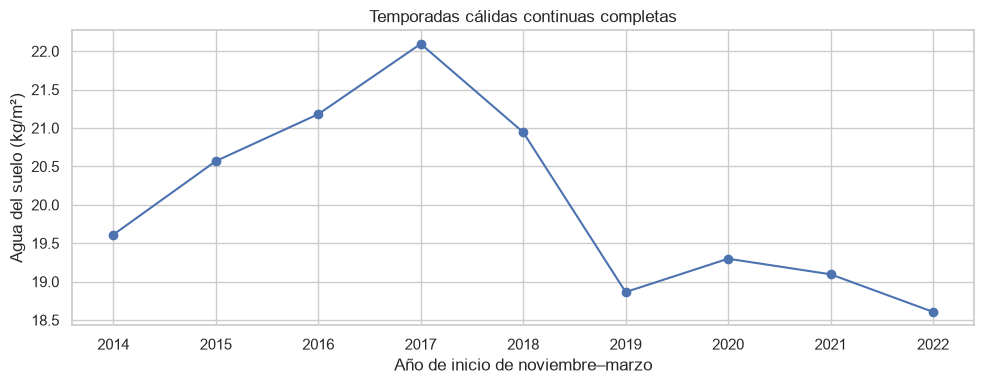

In [7]:
sens_hac=[]
for lag in [6,12,18]:
    for r in ajuste_hac(regional,SUELO,'ventanas',lag):
        sens_hac.append(r)
sens_hac=pd.DataFrame(sens_hac)
display(sens_hac[['ventana','lag_hac','pendiente_anual','ic95_inf','ic95_sup','p']])
loo=[]
for anio in sorted(regional.anio.unique()):
    r=next(r for r in ajuste_hac(regional[regional.anio.ne(anio)],SUELO,'ventanas') if r['ventana']=='nov_mar')
    loo.append(dict(anio_excluido=int(anio),**r))
sens_anios=pd.DataFrame(loo)
display(sens_anios[['anio_excluido','pendiente_anual','ic95_inf','ic95_sup','p']])
calida=regional[regional.mes.isin(CALIDOS)].copy()
calida['inicio_calido']=calida.anio-(calida.mes<=3).astype(int)
veranos=calida.groupby('inicio_calido').agg(meses=(SUELO,'count'),suelo=(SUELO,'mean'),humedad=('relative_humidity_2m_pct','mean'),lluvia=('precipitation_mm','sum'),temperatura=('temperature_2m_c','mean'))
veranos=veranos[veranos.meses.eq(5)]
display(veranos)
pendiente_veranos=stats.theilslopes(veranos.suelo,veranos.index).slope
print(f'Contraste descriptivo Theil–Sen, nueve ventanas completas: {pendiente_veranos:.4f} kg/m²/año. No se usa su IC convencional para inferencia temporal.')
veranos.suelo.plot(marker='o',figsize=(10,4))
plt.ylabel('Agua del suelo (kg/m²)');plt.xlabel('Año de inicio de noviembre–marzo')
plt.title('Temporadas cálidas continuas completas');plt.tight_layout();plt.show()

## 5. ¿Dónde ocurre? Tendencias por comuna
Se estiman las mismas cuatro variables y tres ventanas para todas las comunas. El suelo no utilizable se clasifica como **datos insuficientes**, no como pendiente cero. FDR-BY se aplica a todas las pruebas comunales estimables de este bloque en una familia única; se muestran también p sin ajuste para transparencia, pero las etiquetas de evidencia usan BY.

Las pendientes y los intervalos individuales pueden sugerir patrones incluso cuando BY es conservador. Compartir píxeles significa que contar comunas no mide extensión de superficie ni número de mediciones espaciales independientes.

In [8]:
registros=[]
for codigo,g in comunal.groupby('commune_id'):
    for v in VARS:
        for modelo in ['anual','ventanas']:
            for r in ajuste_hac(g,v,modelo):
                registros.append(dict(commune_id=codigo,comuna=g.commune_name.iloc[0],variable=v,**r))
tendencias_comunas=pd.DataFrame(registros)
validas=tendencias_comunas.estado.eq('estimado')
tendencias_comunas['p_fdr_by']=np.nan
tendencias_comunas.loc[validas,'p_fdr_by']=corregir_p(tendencias_comunas.loc[validas,'p'],'by')
tendencias_comunas['clasificacion']='datos insuficientes'
tendencias_comunas.loc[validas,'clasificacion']='evidencia insuficiente'
tendencias_comunas.loc[validas&tendencias_comunas.p_fdr_by.lt(.05)&tendencias_comunas.pendiente_anual.lt(0),'clasificacion']='descenso con evidencia BY'
tendencias_comunas.loc[validas&tendencias_comunas.p_fdr_by.lt(.05)&tendencias_comunas.pendiente_anual.gt(0),'clasificacion']='aumento con evidencia BY'
print('Familia comunal:',int(validas.sum()),'pruebas válidas.')
suelo_comunas=tendencias_comunas[(tendencias_comunas.variable==SUELO)&(tendencias_comunas.ventana=='nov_mar')].sort_values('pendiente_anual')
display(suelo_comunas[['commune_id','comuna','n','pendiente_anual','ic95_inf','ic95_sup','p','p_fdr_by','clasificacion']])
display(pd.crosstab([tendencias_comunas.variable,tendencias_comunas.ventana],tendencias_comunas.clasificacion))

Familia comunal: 381 pruebas válidas.


,commune_id,comuna,n,pendiente_anual,ic95_inf,ic95_sup,p,p_fdr_by,clasificacion
109,09110,Melipeuco,50,-0.3327,-0.5196,-0.1458,0.0006,0.0177,descenso con evidencia BY
301,09205,Lonquimay,50,-0.3290,-0.4854,-0.1727,0.0001,0.0024,descenso con evidencia BY
277,09203,Curacautín,50,-0.3113,-0.4921,-0.1304,0.0009,0.0224,descenso con evidencia BY
265,09202,Collipulli,50,-0.2533,-0.4436,-0.0630,0.0096,0.1686,evidencia insuficiente
253,09201,Angol,50,-0.2462,-0.4825,-0.0100,0.0412,0.5692,evidencia insuficiente
337,09208,Purén,50,-0.2274,-0.4490,-0.0059,0.0443,0.6048,evidencia insuficiente
313,09206,Los Sauces,50,-0.1837,-0.3949,0.0274,0.0874,0.9609,evidencia insuficiente
37,09104,Curarrehue,50,-0.1787,-0.4314,0.0740,0.1639,1.0000,evidencia insuficiente
169,09115,Pucón,50,-0.1768,-0.4499,0.0964,0.2022,1.0000,evidencia insuficiente
349,09209,Renaico,50,-0.1723,-0.3712,0.0267,0.0889,0.9663,evidencia insuficiente


clasificacion                      aumento con evidencia BY  \
variable                  ventana                             
precipitation_mm          abr_oct                         0   
                          anual                           0   
                          nov_mar                         0   
relative_humidity_2m_pct  abr_oct                         0   
                          anual                           0   
                          nov_mar                         0   
soil_moisture_0_10cm_kgm2 abr_oct                         0   
                          anual                           0   
                          nov_mar                         0   
temperature_2m_c          abr_oct                         0   
                          anual                           0   
                          nov_mar                        14   

clasificacion                      datos insuficientes  \
variable                  ventana                        
precipitation_mm          abr_oct                    0   
                          anual                      0   
                          nov_mar                    0   
relative_humidity_2m_pct  abr_oct                    0   
                          anual                      0   
                          nov_mar                    0   
soil_moisture_0_10cm_kgm2 abr_oct                    1   
                          anual                      1   
                          nov_mar                    1   
temperature_2m_c          abr_oct                    0   
                          anual                      0   
                          nov_mar                    0   

clasificacion                      descenso con evidencia BY  \
variable                  ventana                              
precipitation_mm          abr_oct                          2   
                          anual                            7   
                          nov_mar                          0   
relative_humidity_2m_pct  abr_oct                         32   
                          anual                           32   
                          nov_mar                         31   
soil_moisture_0_10cm_kgm2 abr_oct                          0   
                          anual                            0   
                          nov_mar                          3   
temperature_2m_c          abr_oct                          0   
                          anual                            0   
                          nov_mar                          0   

clasificacion                      evidencia insuficiente  
variable                  ventana                          
precipitation_mm          abr_oct                      30  
                          anual                        25  
                          nov_mar                      32  
relative_humidity_2m_pct  abr_oct                       0  
                          anual                         0  
                          nov_mar                       1  
soil_moisture_0_10cm_kgm2 abr_oct                      31  
                          anual                        31  
                          nov_mar                      28  
temperature_2m_c          abr_oct                      32  
                          anual                        32  
                          nov_mar                      18

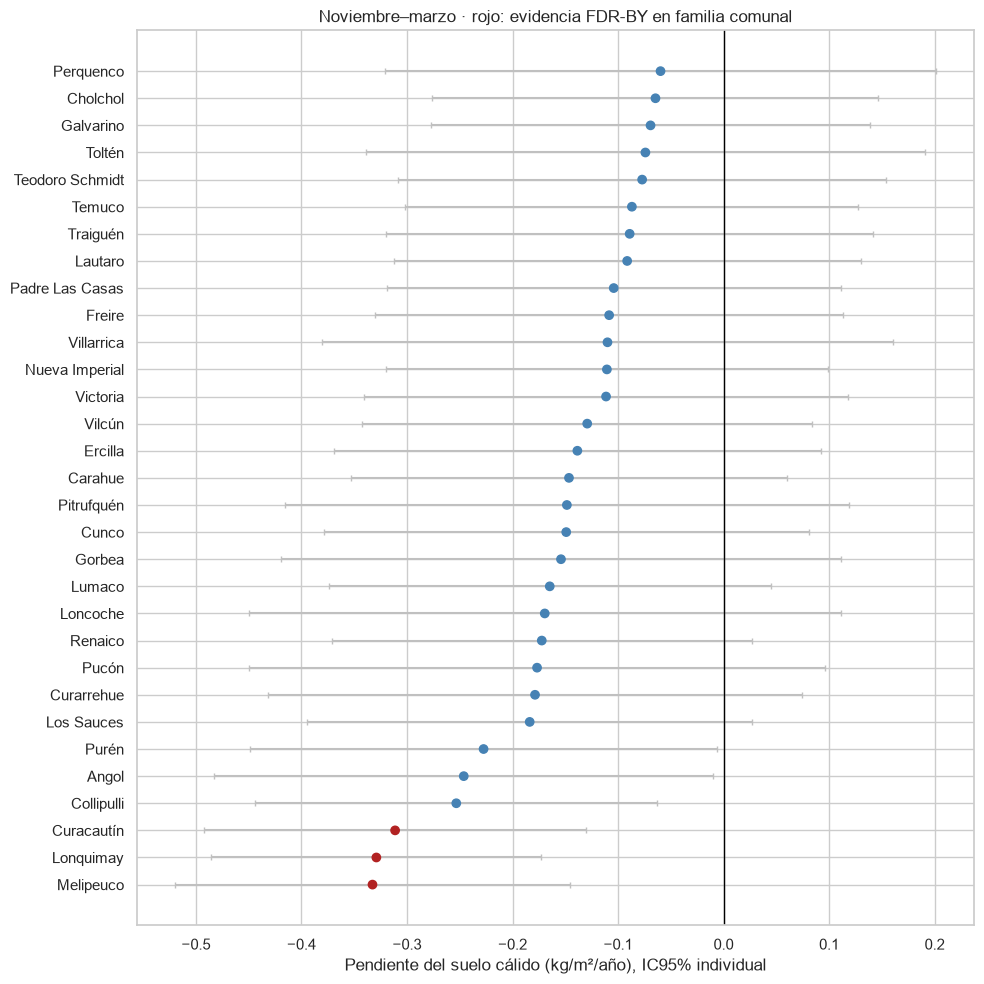

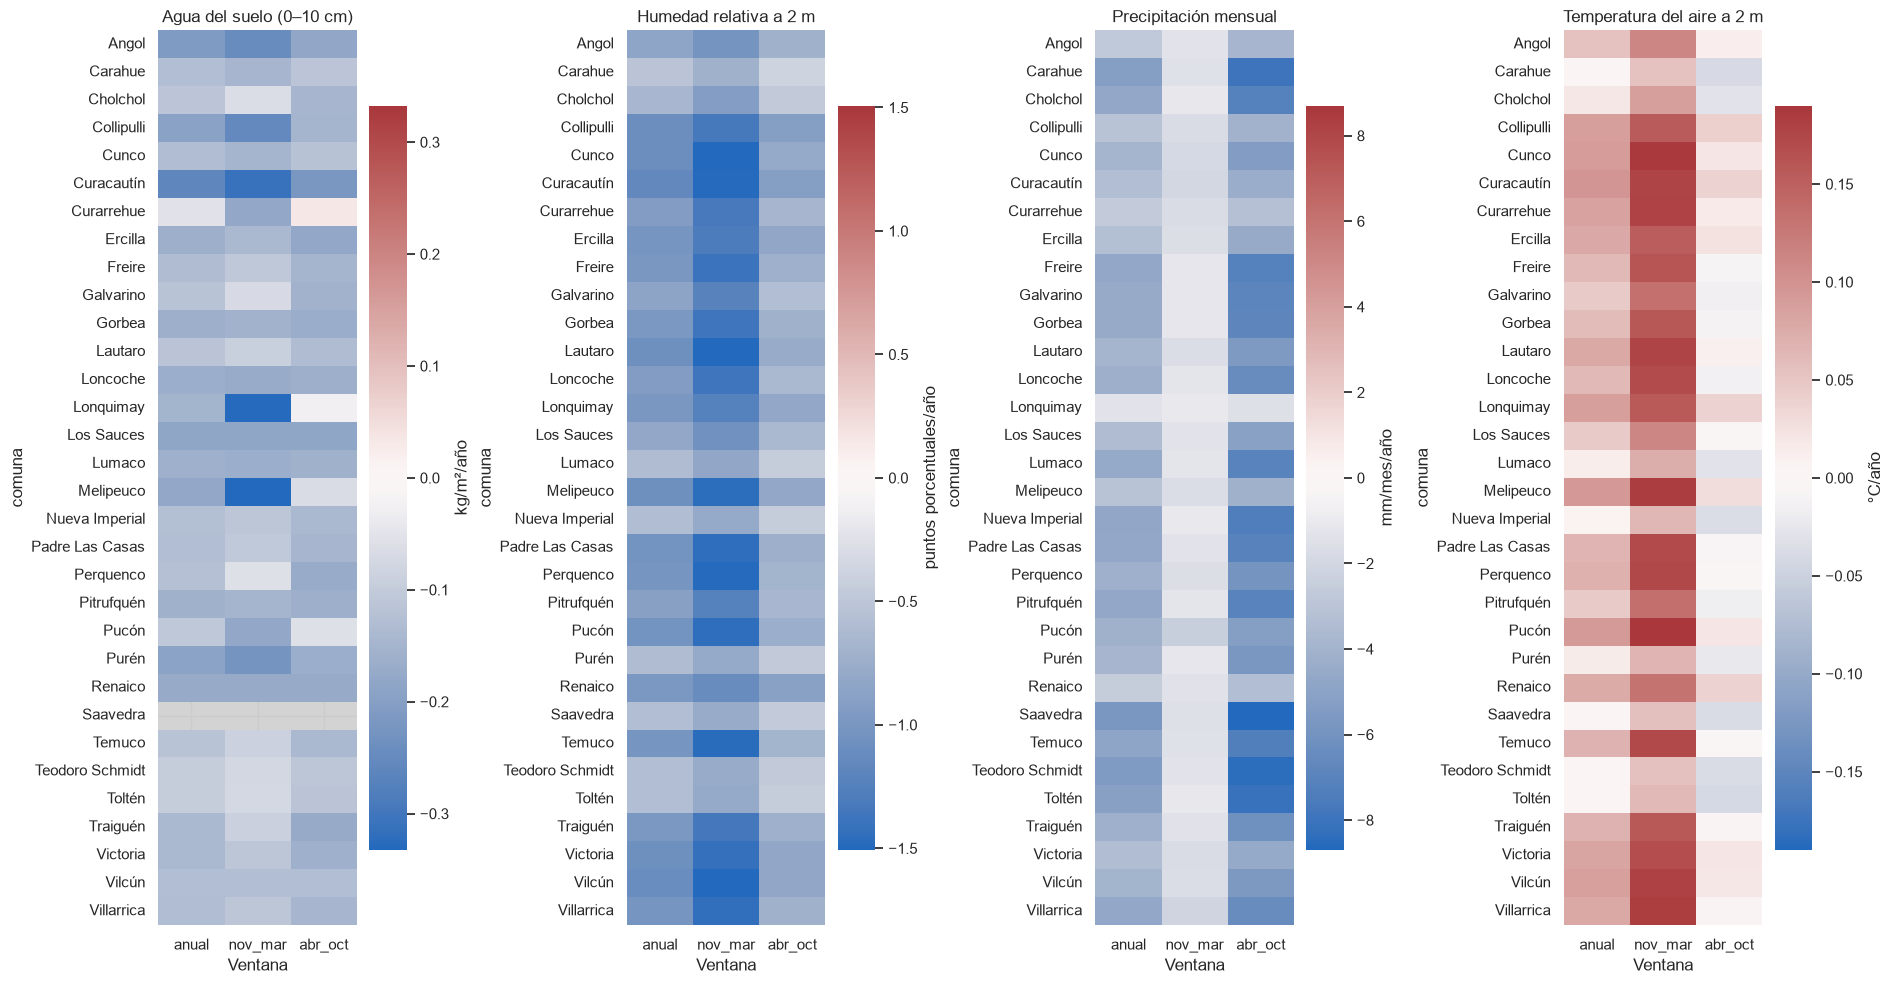

Gris: sin suelo utilizable. Cada panel tiene su propia escala física; los colores no comparan magnitudes entre variables.


In [9]:
t=suelo_comunas[suelo_comunas.estado.eq('estimado')].copy()
fig,ax=plt.subplots(figsize=(10,10))
y=np.arange(len(t))
ax.errorbar(t.pendiente_anual,y,xerr=np.vstack([t.pendiente_anual-t.ic95_inf,t.ic95_sup-t.pendiente_anual]),fmt='none',ecolor='silver',capsize=2)
colores=np.where(t.p_fdr_by.lt(.05),'firebrick','steelblue')
ax.scatter(t.pendiente_anual,y,c=colores,zorder=3)
ax.set_yticks(y,t.comuna);ax.axvline(0,color='black',lw=1)
ax.set(xlabel='Pendiente del suelo cálido (kg/m²/año), IC95% individual',title='Noviembre–marzo · rojo: evidencia FDR-BY en familia comunal')
plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,4,figsize=(19,10))
for ax,v in zip(axs,VARS):
    mat=tendencias_comunas[tendencias_comunas.variable.eq(v)].pivot(index='comuna',columns='ventana',values='pendiente_anual').reindex(columns=['anual','nov_mar','abr_oct'])
    limite=np.nanmax(np.abs(mat.to_numpy()))
    sns.heatmap(mat,cmap='vlag',center=0,vmin=-limite,vmax=limite,ax=ax,cbar_kws={'label':UNIDADES[v]+'/año'})
    ax.set_title(NOMBRES[v]);ax.set_xlabel('Ventana')
    ax.set_facecolor('lightgray')
plt.tight_layout();plt.show()
print('Gris: sin suelo utilizable. Cada panel tiene su propia escala física; los colores no comparan magnitudes entre variables.')

## 6. Sensibilidad a cobertura del suelo
La regla principal del proyecto es 80 %. Al exigir 90 % pueden quedar menos comunas; se compara el mismo estimador sin sustituir sus mediciones por cero. Se informa la cobertura regional por separado: cambiar el subconjunto de comunas no recalcula el producto regional ya agregado.

In [10]:
sens_cobertura=[]
for codigo,g0 in comunal.groupby('commune_id'):
    for umbral in [80,90]:
        g=g0.copy()
        g.loc[g.suelo_mensual_valid_area_pct.lt(umbral),SUELO]=np.nan
        r=next(x for x in ajuste_hac(g,SUELO,'ventanas') if x['ventana']=='nov_mar')
        sens_cobertura.append(dict(comuna=g.commune_name.iloc[0],umbral_pct=umbral,**r))
sens_cobertura=pd.DataFrame(sens_cobertura)
display(sens_cobertura.groupby('umbral_pct').agg(comunas_estimables=('estado',lambda x:int(x.eq('estimado').sum())),mediana_pendiente=('pendiente_anual','median')))
display(sens_cobertura[sens_cobertura.comuna.isin(['Saavedra','Teodoro Schmidt'])][['comuna','umbral_pct','estado','n','pendiente_anual']])
print('Cobertura regional mínima:',regional.suelo_mensual_valid_area_pct.min(),'%')

,comunas_estimables,mediana_pendiente
umbral_pct,,
80,31,-0.1465
90,30,-0.1475


,comuna,umbral_pct,estado,n,pendiente_anual
30,Saavedra,80,datos insuficientes,0,NaN
31,Saavedra,90,datos insuficientes,0,NaN
32,Teodoro Schmidt,80,estimado,50,-0.0772
33,Teodoro Schmidt,90,datos insuficientes,0,NaN


Cobertura regional mínima: 98.85 %


## 7. Interpretación ambiental: coincidencia no es explicación causal
Se comparan anomalías de suelo con humedad relativa, lluvia y temperatura, y precipitación previa con suelo actual. Son asociaciones descriptivas, no pruebas adicionales de tendencia. Las climatologías usan todo 2014–2023 y no deben reutilizarse así para pronóstico. La lluvia de t−k se desplaza dentro de la serie mensual completa antes del cruce.

,soil_moisture_0_10cm_kgm2,relative_humidity_2m_pct,precipitation_mm,temperature_2m_c
soil_moisture_0_10cm_kgm2,1.0000,0.5835,0.4870,-0.5696
relative_humidity_2m_pct,0.5835,1.0000,0.5693,-0.5175
precipitation_mm,0.4870,0.5693,1.0000,-0.2804
temperature_2m_c,-0.5696,-0.5175,-0.2804,1.0000


,rezago_meses,n,rho_lluvia_previa_suelo
0,0,120,0.4870
1,1,119,0.5299
2,2,118,0.4246
3,3,117,0.3915


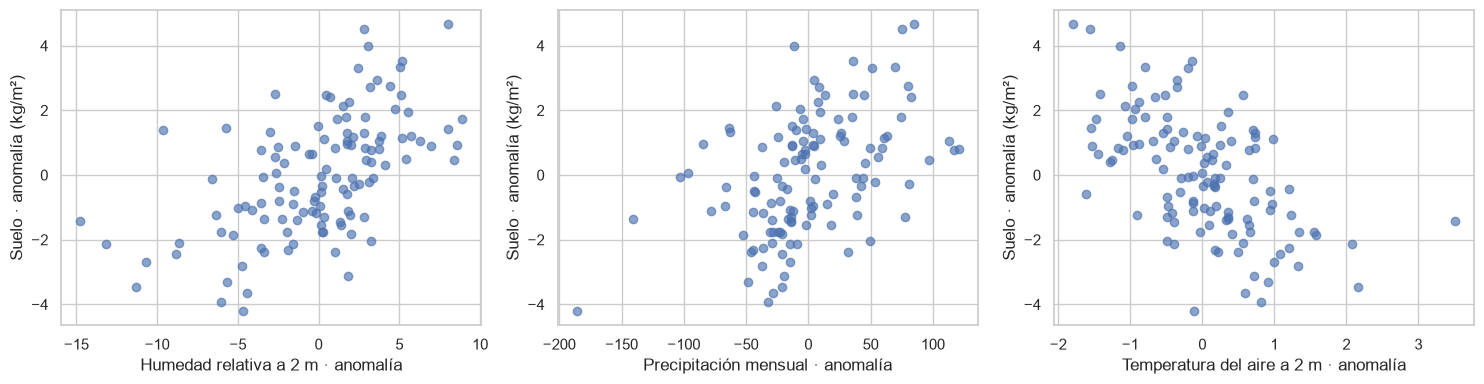

In [11]:
anom_r=regional[VARS]-regional.groupby('mes')[VARS].transform('mean')
display(anom_r.corr(method='spearman'))
rezagos=[]
for k in range(4):
    anterior=anom_r.precipitation_mm.shift(k)
    valido=anterior.notna()&anom_r[SUELO].notna()
    rezagos.append({'rezago_meses':k,'n':int(valido.sum()),'rho_lluvia_previa_suelo':anterior[valido].corr(anom_r.loc[valido,SUELO],method='spearman')})
display(pd.DataFrame(rezagos))
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,v in zip(axs,VARS[1:]):
    ax.scatter(anom_r[v],anom_r[SUELO],alpha=.65)
    ax.set(xlabel=NOMBRES[v]+' · anomalía',ylabel='Suelo · anomalía (kg/m²)')
plt.tight_layout();plt.show()

## 8. Contexto CONAF: ¿los meses con menos agua del suelo presentan más incendios?
Se usa CONAF **regional mensual**, no se desagregan totales comunales de temporada. Enero de 2014–2015 se fecha como enero de 2015. La comparación conserva la intersección de **114 meses**, julio de 2014–diciembre de 2023, sin rellenar ausencias con cero.

Los rezagos evalúan suelo en t−k frente a incendios en t; se permiten antecedentes ambientales de enero–junio de 2014 aunque no haya CONAF en esos meses. Se calculan anomalías ambientales sobre 2014–2023 y anomalías CONAF sobre su intersección válida. Se añade un contraste tras retirar una tendencia lineal y el ciclo mensual de cada serie para advertir asociaciones explicadas por evolución común. Ninguna variante demuestra anticipación validada, causalidad ni relación con superficie quemada.

,rezago_suelo_meses,n,rho_original,rho_anomalias,rho_sin_ciclo_ni_tendencia
0,0,114,-0.8775,-0.6376,-0.6051
1,1,114,-0.5712,-0.2706,-0.2532
2,2,114,-0.1576,-0.1927,-0.1266
3,3,114,0.2842,-0.1615,-0.0814


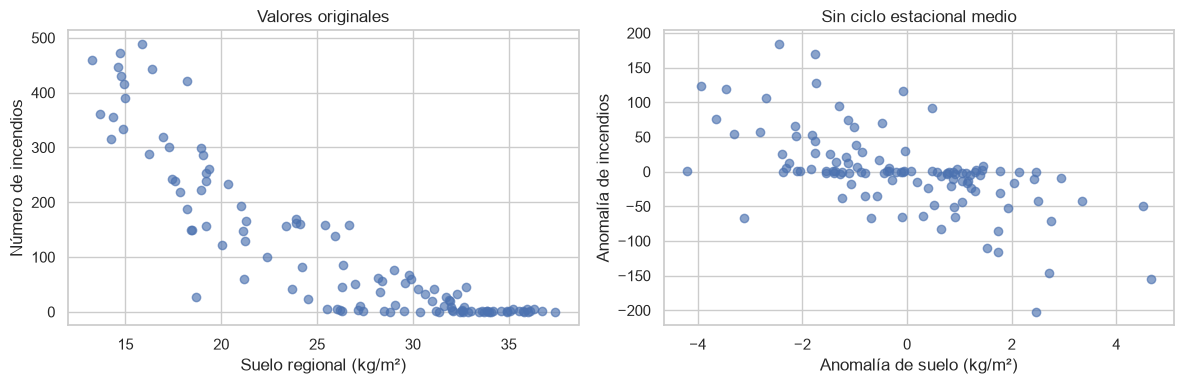

In [12]:
conaf=pd.read_csv(RAIZ/'data/conaf/conaf.csv')
meses_nombres=['ENERO','FEBRERO','MARZO','ABRIL','MAYO','JUNIO','JULIO','AGOSTO','SEPTIEMBRE','OCTUBRE','NOVIEMBRE','DICIEMBRE']
conaf['mes']=conaf.mes.str.upper().str.strip().map({m:i+1 for i,m in enumerate(meses_nombres)})
assert conaf.mes.notna().all()
inicio=conaf.temporada.str.split('-').str[0].astype(int)
conaf['fecha']=pd.to_datetime(pd.DataFrame({'year':inicio+(conaf.mes<=6).astype(int),'month':conaf.mes,'day':1}))
conaf=conaf[['fecha','IX']].rename(columns={'IX':'incendios'})
assert not conaf.fecha.duplicated().any()
cruce=regional[['fecha','mes','anio','indice_mes',SUELO]].merge(conaf,on='fecha',how='inner',validate='one_to_one')
assert len(cruce)==114 and cruce.incendios.notna().all()
cruce['anom_incendios']=cruce.incendios-cruce.groupby('mes').incendios.transform('mean')
def retirar_ciclo_tendencia(g,col):
    X=np.column_stack([pd.get_dummies(g.mes,dtype=float).to_numpy(),g.indice_mes.to_numpy()/12])
    return g[col].to_numpy()-X@np.linalg.lstsq(X,g[col].to_numpy(),rcond=None)[0]
resid_suelo=retirar_ciclo_tendencia(regional,SUELO)
resid_incendios=retirar_ciclo_tendencia(cruce,'incendios')
filas=[]
for k in range(4):
    origen=pd.DataFrame({'fecha':regional.fecha,'suelo_previo':regional[SUELO].shift(k),'anom_suelo_previo':anom_r[SUELO].shift(k),'resid_suelo_previo':pd.Series(resid_suelo).shift(k)})
    t=cruce.merge(origen,on='fecha',validate='one_to_one')
    t['resid_incendios']=resid_incendios
    t=t.dropna()
    filas.append({'rezago_suelo_meses':k,'n':len(t),'rho_original':t.suelo_previo.corr(t.incendios,method='spearman'),
      'rho_anomalias':t.anom_suelo_previo.corr(t.anom_incendios,method='spearman'),
      'rho_sin_ciclo_ni_tendencia':t.resid_suelo_previo.corr(t.resid_incendios,method='spearman')})
relacion_conaf=pd.DataFrame(filas)
display(relacion_conaf)
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].scatter(cruce[SUELO],cruce.incendios,alpha=.65)
axs[0].set(xlabel='Suelo regional (kg/m²)',ylabel='Número de incendios',title='Valores originales')
t=cruce.merge(pd.DataFrame({'fecha':regional.fecha,'anom_suelo':anom_r[SUELO]}),on='fecha')
axs[1].scatter(t.anom_suelo,t.anom_incendios,alpha=.65)
axs[1].set(xlabel='Anomalía de suelo (kg/m²)',ylabel='Anomalía de incendios',title='Sin ciclo estacional medio')
plt.tight_layout();plt.show()

## 9. Conclusión: respuesta a la pregunta y justificación
La conclusión se construye a partir de la prueba primaria, la corrección regional, la sensibilidad temporal y la consistencia comunal. Un descenso estimado sin evidencia suficiente se distingue de un descenso respaldado por el método. No se exige que otras variables resulten significativas para aceptar el resultado primario, ni se usa la correlación con incendios para “validar” una tendencia.

In [13]:
r=primaria
if r.pendiente_anual<0 and r.p<.05:
    respuesta='Sí: hay evidencia estadística aproximada de una disminución regional del agua superficial del suelo durante noviembre–marzo en 2014–2023, bajo el modelo y la corrección temporal especificados.'
elif r.pendiente_anual<0:
    respuesta='La pendiente estimada apunta a menor agua superficial del suelo en noviembre–marzo, pero la evidencia estadística no permite afirmar un secamiento regional sostenido con el criterio principal.'
else:
    respuesta='Este análisis no respalda un secamiento regional del suelo durante noviembre–marzo: la pendiente estimada no es negativa. Esto no demuestra ausencia de episodios secos ni de cambios locales.'
validas_s=suelo_comunas[suelo_comunas.estado.eq('estimado')]
neg=int(validas_s.pendiente_anual.lt(0).sum())
neg_by=int((validas_s.pendiente_anual.lt(0)&validas_s.p_fdr_by.lt(.05)).sum())
loo_min=sens_anios.pendiente_anual.min();loo_max=sens_anios.pendiente_anual.max()
lag_principal=sens_hac[sens_hac.ventana.eq('nov_mar')]
estable_hac=bool(lag_principal.ic95_sup.lt(0).all())
clima=tendencias_region[(tendencias_region.ventana=='nov_mar')&(tendencias_region.variable!=SUELO)]
lineas=[f'**Respuesta:** {respuesta}',
 f'**Magnitud:** {r.pendiente_anual:.3f} kg/m²/año; IC95% HAC [{r.ic95_inf:.3f}, {r.ic95_sup:.3f}]; p bilateral = {r.p:.4f}. El cambio lineal estimado entre meses equivalentes de 2014 y 2023 es {r.cambio_estimado_9anios:.3f} kg/m²: no es una resta de dos mediciones aisladas.',
 f'**Multiplicidad regional:** p Holm = {r.p_holm_regional:.4f}. '+('El descenso conserva evidencia dentro de las 12 comparaciones regionales.' if r.p_holm_regional<.05 and r.pendiente_anual<0 else 'No se sostiene un descenso con evidencia tras considerar las 12 comparaciones regionales; se diferencia ese resultado de la prueba primaria predefinida.'),
 f'**Sensibilidad temporal:** al excluir un año, la pendiente cálida varía entre {loo_min:.3f} y {loo_max:.3f} kg/m²/año. '+('Todos esos estimados son negativos.' if loo_max<0 else 'El signo no es estable al excluir años.')+' '+('El IC queda por debajo de cero con HAC de 6, 12 y 18 meses.' if estable_hac else 'Los intervalos HAC de 6, 12 y 18 meses no respaldan uniformemente un descenso distinto de cero.'),
 f'**Territorio:** {neg} de {len(validas_s)} comunas utilizables tienen pendiente cálida negativa; {neg_by} presentan descenso con evidencia FDR-BY en la familia comunal completa. Saavedra no se cuenta como ausencia de cambio: no tiene suelo con cobertura suficiente. Las comunas no son réplicas espaciales independientes.',
 f'**Ventanas cálidas continuas:** las nueve temporadas completas dan una pendiente descriptiva Theil–Sen de {pendiente_veranos:.3f} kg/m²/año, contraste adicional sin una segunda declaración de significancia.']
for _,x in clima.iterrows():
    evidencia='con evidencia Holm' if x.p_holm_regional<.05 else 'sin evidencia Holm suficiente'
    lineas.append(f'**Contexto — {NOMBRES[x.variable]}:** {x.pendiente_anual:+.3f} {UNIDADES[x.variable]}/año en noviembre–marzo, {evidencia}. Una coincidencia de tendencias no establece el mecanismo causal del suelo.')
c0=relacion_conaf.iloc[0]
lineas.append(f'**Conexión con incendios:** la asociación contemporánea suelo–incendios es {c0.rho_anomalias:.3f} entre anomalías y {c0.rho_sin_ciclo_ni_tendencia:.3f} tras retirar también tendencias lineales. Estos coeficientes describen coexistencia, no demuestran que el cambio del suelo cause el cambio de incendios ni que sirva para pronosticarlos fuera de muestra.')

comunas_evidencia=validas_s.loc[validas_s.pendiente_anual.lt(0)&validas_s.p_fdr_by.lt(.05),'comuna'].tolist()
lineas.append('**Descensos comunales con evidencia BY:** '+(', '.join(comunas_evidencia) if comunas_evidencia else 'ninguno con el criterio adoptado')+'. No se extrapola ese resultado a las comunas excluidas ni a predios individuales.')
humedad=clima[clima.variable.eq('relative_humidity_2m_pct')].iloc[0]
calor=clima[clima.variable.eq('temperature_2m_c')].iloc[0]
if humedad.pendiente_anual<0 and humedad.p_holm_regional<.05 and calor.pendiente_anual>0 and calor.p_holm_regional<.05:
    lineas.insert(0,'**Balance conjunto:** sí hay señales de aire más cálido y menor humedad relativa durante noviembre–marzo en este período. Eso respalda hablar de cambios en las condiciones atmosféricas cálidas; la evidencia regional de secamiento del suelo sigue siendo insuficiente al 5 %. La humedad relativa también depende de la temperatura, por lo que su descenso no demuestra por sí solo una reducción del vapor de agua ni confirma sequía integral.')
else:
    lineas.insert(0,'**Balance conjunto:** las variables deben interpretarse por separado según sus pendientes e incertidumbre; no se declara un secamiento general únicamente por el signo de varias estimaciones.')

display(Markdown((chr(10)*2).join(lineas)))

**Balance conjunto:** sí hay señales de aire más cálido y menor humedad relativa durante noviembre–marzo en este período. Eso respalda hablar de cambios en las condiciones atmosféricas cálidas; la evidencia regional de secamiento del suelo sigue siendo insuficiente al 5 %. La humedad relativa también depende de la temperatura, por lo que su descenso no demuestra por sí solo una reducción del vapor de agua ni confirma sequía integral.

**Respuesta:** La pendiente estimada apunta a menor agua superficial del suelo en noviembre–marzo, pero la evidencia estadística no permite afirmar un secamiento regional sostenido con el criterio principal.

**Magnitud:** -0.182 kg/m²/año; IC95% HAC [-0.375, 0.010]; p bilateral = 0.0633. El cambio lineal estimado entre meses equivalentes de 2014 y 2023 es -1.640 kg/m²: no es una resta de dos mediciones aisladas.

**Multiplicidad regional:** p Holm = 0.4434. No se sostiene un descenso con evidencia tras considerar las 12 comparaciones regionales; se diferencia ese resultado de la prueba primaria predefinida.

**Sensibilidad temporal:** al excluir un año, la pendiente cálida varía entre -0.242 y -0.136 kg/m²/año. Todos esos estimados son negativos. Los intervalos HAC de 6, 12 y 18 meses no respaldan uniformemente un descenso distinto de cero.

**Territorio:** 31 de 31 comunas utilizables tienen pendiente cálida negativa; 3 presentan descenso con evidencia FDR-BY en la familia comunal completa. Saavedra no se cuenta como ausencia de cambio: no tiene suelo con cobertura suficiente. Las comunas no son réplicas espaciales independientes.

**Ventanas cálidas continuas:** las nueve temporadas completas dan una pendiente descriptiva Theil–Sen de -0.250 kg/m²/año, contraste adicional sin una segunda declaración de significancia.

**Contexto — Humedad relativa a 2 m:** -1.254 puntos porcentuales/año en noviembre–marzo, con evidencia Holm. Una coincidencia de tendencias no establece el mecanismo causal del suelo.

**Contexto — Precipitación mensual:** -1.523 mm/mes/año en noviembre–marzo, sin evidencia Holm suficiente. Una coincidencia de tendencias no establece el mecanismo causal del suelo.

**Contexto — Temperatura del aire a 2 m:** +0.146 °C/año en noviembre–marzo, con evidencia Holm. Una coincidencia de tendencias no establece el mecanismo causal del suelo.

**Conexión con incendios:** la asociación contemporánea suelo–incendios es -0.638 entre anomalías y -0.605 tras retirar también tendencias lineales. Estos coeficientes describen coexistencia, no demuestran que el cambio del suelo cause el cambio de incendios ni que sirva para pronosticarlos fuera de muestra.

**Descensos comunales con evidencia BY:** Melipeuco, Lonquimay, Curacautín. No se extrapola ese resultado a las comunas excluidas ni a predios individuales.

### Decisión para el proyecto

- Presentar en la futura interfaz **pendiente, período, intervalo y evidencia**, con “datos insuficientes” separado de “evidencia insuficiente”. Conservar el resultado aunque no sea significativo.
- Usar las coincidencias entre suelo, aire, lluvia y calor para formular hipótesis, sin inferir un mecanismo completo de sequía ni identificar humedad de combustible.
- Si se evalúa anticipación, construir antecedentes de suelo y lluvia de uno a tres meses y compararlos con una referencia estacional en validación temporal. Climatologías, tendencias y selección de variables se recalculan solo con entrenamiento.
- No extrapolar una recta de diez años como escenario climático futuro ni convertirla en alerta operacional. La significancia depende del modelo, la aproximación HAC y el período; la sensibilidad ayuda a hacer visibles esas limitaciones.

**Producto entregado:** tabla regional de tendencias; tabla comunal con códigos, ventanas, pendientes, intervalos y FDR; sensibilidad a cobertura y dependencia temporal; gráficos y conclusión calculada. Todos permanecen en memoria y en las salidas de este notebook.

In [14]:
assert all(hashlib.sha256(Path(f).read_bytes()).hexdigest()==h for f,h in hashes_inicio.items())
assert tendencias_region.shape[0]==12
assert tendencias_comunas.shape[0]==32*4*3
assert suelo_comunas.loc[suelo_comunas.comuna.eq('Saavedra'),'estado'].eq('datos insuficientes').all()
print('Análisis completo. Fuentes conservadas sin cambios; resultados contenidos en este notebook.')

Análisis completo. Fuentes conservadas sin cambios; resultados contenidos en este notebook.


# 10. Nuevo cruce `conaf_nasa.csv`: suelo e incendios observados

Este bloque amplía las conclusiones anteriores sin sustituirlas. **Pregunta:** ¿qué relación tiene el agua del suelo con el número de incendios regionales y qué información aporta antes del mes analizado?

Se distingue una asociación contemporánea, que describe coexistencia, de un antecedente disponible un mes antes. No se interpreta el conteo como intencionalidad, intentos de ignición, propagación o superficie quemada: esas variables no están en el CSV. El bloque es autónomo y no modifica archivos de datos.

In [15]:
%matplotlib inline
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy.special import xlogy
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns',25)
pd.set_option('display.float_format',lambda x:f'{x:.4f}')
ROOT_N=next(q for q in [Path.cwd(),*Path.cwd().parents] if (q/'conaf_nasa.csv').exists() or (q/'DeHecho/conaf_nasa.csv').exists())
if not (ROOT_N/'conaf_nasa.csv').exists():ROOT_N=ROOT_N/'DeHecho'
CSV_N=ROOT_N/'conaf_nasa.csv'
HASH_N=hashlib.sha256(CSV_N.read_bytes()).hexdigest()
original_n=pd.read_csv(CSV_N)
nuevo=original_n.copy()
S_N='soil_moisture_0_10cm_kgm2'
I_N='cantidad_incendios'
meses_n=['ENERO','FEBRERO','MARZO','ABRIL','MAYO','JUNIO','JULIO','AGOSTO','SEPTIEMBRE','OCTUBRE','NOVIEMBRE','DICIEMBRE']
nuevo['mes_n']=nuevo.mes.str.strip().str.upper().map({x:i+1 for i,x in enumerate(meses_n)})
assert nuevo.mes_n.notna().all()
# En este CSV “año” es el año inicial de la temporada, no siempre el año calendario.
nuevo['fecha_reconstruida']=pd.to_datetime(pd.DataFrame({'year':nuevo['año']+(nuevo.mes_n<=6).astype(int),'month':nuevo.mes_n,'day':1}))
nuevo['fecha_nasa']=pd.to_datetime(nuevo.month,format='%Y-%m',errors='coerce')
assert nuevo.loc[nuevo.fecha_nasa.notna(),'fecha_reconstruida'].eq(nuevo.loc[nuevo.fecha_nasa.notna(),'fecha_nasa']).all()
assert not nuevo.fecha_reconstruida.duplicated().any()
assert nuevo[I_N].notna().all() and nuevo[I_N].ge(0).all() and nuevo[I_N].mod(1).eq(0).all()
reporte_n=json.loads((ROOT_N/'datos_mensuales_2014_2023/limpios/reporte_validacion.json').read_text(encoding='utf-8-sig'))
utilizable=nuevo[S_N].notna()&nuevo.fecha_nasa.notna()&nuevo.suelo_mensual_valid_area_pct.ge(float(reporte_n['soil_coverage_threshold_pct']))
datos_n=nuevo.loc[utilizable].copy().sort_values('fecha_reconstruida').reset_index(drop=True)
datos_n['fecha']=datos_n.fecha_reconstruida
datos_n['anio_n']=datos_n.fecha.dt.year
datos_n['mes_n']=datos_n.fecha.dt.month
datos_n['tiempo_n']=(datos_n.anio_n-2014)+(datos_n.mes_n-1)/12
assert len(datos_n)==114
assert datos_n.fecha.tolist()==pd.date_range('2014-07-01','2023-12-01',freq='MS').tolist()
print('CSV:',len(nuevo),'filas | pares suelo-incendios utilizables:',len(datos_n))
print('Período válido:',datos_n.fecha.min().date(),'a',datos_n.fecha.max().date())
display(nuevo.loc[~utilizable,['año','mes','fecha_reconstruida',I_N,'month',S_N]])
# Trazabilidad: el nuevo archivo contiene el mismo ambiente regional y los mismos conteos.
ref_n=pd.read_csv(ROOT_N/'datos_mensuales_2014_2023/limpios/region_mensual_limpio.csv')
verif_n=datos_n[['month',S_N]].merge(ref_n[['month',S_N]],on='month',suffixes=('_nuevo','_previo'),validate='one_to_one')
assert np.allclose(verif_n[S_N+'_nuevo'],verif_n[S_N+'_previo'])
conaf_ref_n=pd.read_csv(ROOT_N/'data/conaf/conaf.csv')
conaf_ref_n['mes_n']=conaf_ref_n.mes.map({x:i+1 for i,x in enumerate(meses_n)})
inicio_n=conaf_ref_n.temporada.str[:4].astype(int)
conaf_ref_n['fecha']=pd.to_datetime(pd.DataFrame({'year':inicio_n+(conaf_ref_n.mes_n<=6).astype(int),'month':conaf_ref_n.mes_n,'day':1}))
verif_conteos=datos_n[['fecha',I_N]].merge(conaf_ref_n[['fecha','IX']],on='fecha',validate='one_to_one')
assert verif_conteos[I_N].eq(verif_conteos.IX).all()
print('Suelo y conteos coinciden con las fuentes anteriores: no son observaciones independientes nuevas.')

CSV: 120 filas | pares suelo-incendios utilizables: 114
Período válido: 2014-07-01 a 2023-12-01


,año,mes,fecha_reconstruida,cantidad_incendios,month,soil_moisture_0_10cm_kgm2
114,2023,ENERO,2024-01-01,317.0000,NaN,NaN
115,2023,FEBRERO,2024-02-01,384.0000,NaN,NaN
116,2023,MARZO,2024-03-01,308.0000,NaN,NaN
117,2023,ABRIL,2024-04-01,84.0000,NaN,NaN
118,2023,MAYO,2024-05-01,1.0000,NaN,NaN
119,2023,JUNIO,2024-06-01,0.0000,NaN,NaN


Suelo y conteos coinciden con las fuentes anteriores: no son observaciones independientes nuevas.


## 10.1. Qué aporta el archivo y qué no

Las 120 filas corresponden a diez temporadas CONAF. **Solo 114 tienen NASA:** las seis de enero–junio de 2024 conservan incendios, pero carecen de ambiente. Se dejan fuera del análisis conjunto, sin imputar suelo ni transformar faltantes en cero. El campo `año=2014, mes=ENERO` corresponde a enero de **2015**, como confirma `month`.

Este CSV facilita el análisis porque ya trae el cruce; no amplía la cobertura ambiental ni constituye una validación independiente de las conclusiones previas. Las tendencias de 2014–2023 se conservan arriba con 120 meses ambientales; aquí se estudian asociaciones con incendios en su intersección.

## 10.2. Asociación contemporánea, ciclo anual y tendencia común
Las anomalías se calculan respecto del promedio de cada mes en los **114 meses conjuntos**. Por eso sus coeficientes pueden diferir ligeramente de los anteriores, cuya climatología ambiental utilizaba 120 meses. La tercera comparación retira mes calendario y tendencia lineal de cada serie. Estas transformaciones son descriptivas y usan todo el período; la evaluación predictiva posterior construye sus referencias exclusivamente en entrenamiento.

,comparacion,n,spearman
0,Original,114,-0.8775
1,Anomalías de mes calendario,114,-0.6304
2,Residuos sin mes ni tendencia lineal,114,-0.5931


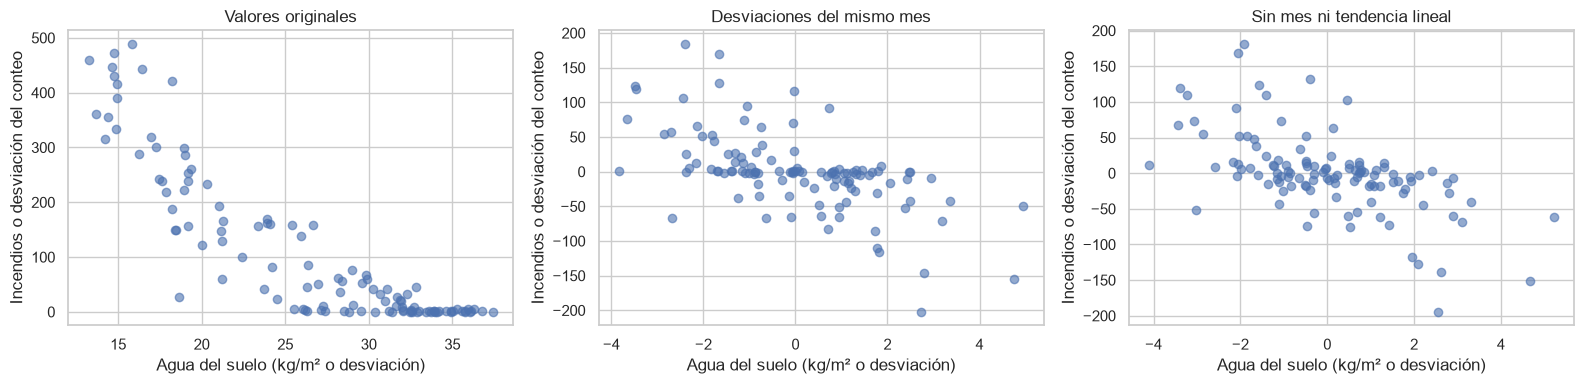

In [16]:
datos_n['anom_suelo']=datos_n[S_N]-datos_n.groupby('mes_n')[S_N].transform('mean')
datos_n['anom_incendios']=datos_n[I_N]-datos_n.groupby('mes_n')[I_N].transform('mean')
def residuo_n(serie,marco):
    X=np.column_stack([pd.get_dummies(marco.mes_n,dtype=float).to_numpy(),marco.tiempo_n.to_numpy()])
    return pd.Series(serie.to_numpy()-X@np.linalg.lstsq(X,serie.to_numpy(),rcond=None)[0],index=marco.index)
datos_n['resid_suelo']=residuo_n(datos_n[S_N],datos_n)
datos_n['resid_incendios']=residuo_n(datos_n[I_N],datos_n)
asociaciones_n=pd.DataFrame([
 {'comparacion':'Original','n':len(datos_n),'spearman':datos_n[S_N].corr(datos_n[I_N],method='spearman')},
 {'comparacion':'Anomalías de mes calendario','n':len(datos_n),'spearman':datos_n.anom_suelo.corr(datos_n.anom_incendios,method='spearman')},
 {'comparacion':'Residuos sin mes ni tendencia lineal','n':len(datos_n),'spearman':datos_n.resid_suelo.corr(datos_n.resid_incendios,method='spearman')}])
display(asociaciones_n)
fig,axs=plt.subplots(1,3,figsize=(16,4))
for ax,(x,y,titulo) in zip(axs,[(S_N,I_N,'Valores originales'),('anom_suelo','anom_incendios','Desviaciones del mismo mes'),('resid_suelo','resid_incendios','Sin mes ni tendencia lineal')]):
    ax.scatter(datos_n[x],datos_n[y],alpha=.6)
    ax.set(xlabel='Agua del suelo (kg/m² o desviación)',ylabel='Incendios o desviación del conteo',title=titulo)
plt.tight_layout();plt.show()

## 10.3. Meses relativamente secos y húmedos: comparación dentro del calendario
Se ordena el suelo dentro de cada mes calendario y se comparan tercios. Así, un enero seco se compara con otros eneros y no con un julio. Se muestran diferencias de conteos y sus promedios con **igual peso por mes calendario**; no son tasas ajustadas por intentos humanos ni un experimento causal.

La clasificación es retrospectiva, depende de todo el período y de nueve o diez observaciones por mes. No se reutiliza para predecir. Noviembre–marzo se mantiene como ventana cálida ya declarada en el análisis previo.

grupo_suelo,Húmedo,Intermedio,Seco,diferencia_seco_menos_humedo
mes_n,,,,
1,251.3333,314.0000,348.6667,97.3333
2,278.6667,364.6667,413.3333,134.6667
3,164.0000,401.3333,344.0000,180.0000
4,36.6667,115.6667,131.6667,95.0000
5,4.6667,4.6667,4.3333,-0.3333
6,0.0000,1.0000,1.0000,1.0000
7,0.3333,0.6667,0.7500,0.4167
8,2.0000,3.0000,2.5000,0.5000
9,2.3333,16.6667,25.2500,22.9167


,ventana,grupo,n_observaciones,media_incendios_igual_peso_mes
0,Todos,Seco,42,139.9375
1,Todos,Intermedio,36,119.3056
2,Todos,Húmedo,36,77.6389
3,Noviembre–marzo,Seco,17,290.4500
4,Noviembre–marzo,Intermedio,15,253.8667
5,Noviembre–marzo,Húmedo,15,176.2000


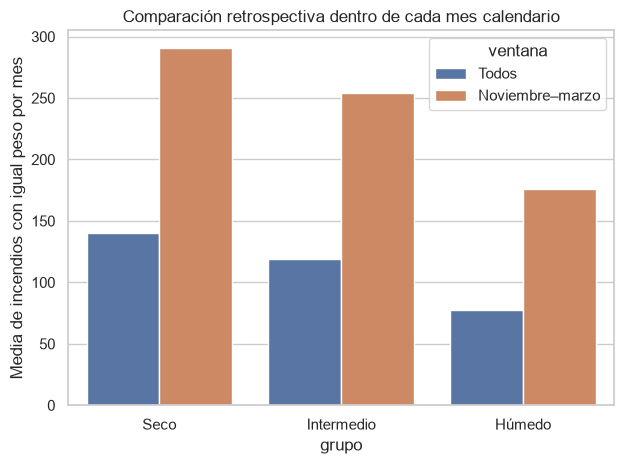

In [17]:
comparacion_n=datos_n.sort_values(['mes_n',S_N,'fecha']).copy()
# Para 9 observaciones: 3/3/3; para 10: 4/3/3, diferencia explicitada en las tablas.
comparacion_n['orden_suelo']=comparacion_n.groupby('mes_n').cumcount()
comparacion_n['n_mes']=comparacion_n.groupby('mes_n')[S_N].transform('size')
comparacion_n['grupo_suelo']=np.floor(3*comparacion_n.orden_suelo/comparacion_n.n_mes).map({0:'Seco',1:'Intermedio',2:'Húmedo'})
por_mes_n=comparacion_n.groupby(['mes_n','grupo_suelo']).agg(n=(I_N,'size'),incendios_media=(I_N,'mean'),suelo_media=(S_N,'mean')).reset_index()
contraste_n=por_mes_n.pivot(index='mes_n',columns='grupo_suelo',values='incendios_media')
contraste_n['diferencia_seco_menos_humedo']=contraste_n.Seco-contraste_n['Húmedo']
display(contraste_n)
resumen_grupos_n=[]
for ventana,meses in [('Todos',list(range(1,13))),('Noviembre–marzo',[11,12,1,2,3])]:
    for grupo in ['Seco','Intermedio','Húmedo']:
        t=por_mes_n[por_mes_n.mes_n.isin(meses)&por_mes_n.grupo_suelo.eq(grupo)]
        resumen_grupos_n.append({'ventana':ventana,'grupo':grupo,'n_observaciones':int(t.n.sum()),'media_incendios_igual_peso_mes':t.incendios_media.mean()})
resumen_grupos_n=pd.DataFrame(resumen_grupos_n)
display(resumen_grupos_n)
sns.barplot(data=resumen_grupos_n,x='grupo',y='media_incendios_igual_peso_mes',hue='ventana',order=['Seco','Intermedio','Húmedo'])
plt.ylabel('Media de incendios con igual peso por mes');plt.title('Comparación retrospectiva dentro de cada mes calendario')
plt.tight_layout();plt.show()

## 10.4. ¿El suelo seco antecede al conteo o coincide principalmente con él?
Se compara suelo de t−k con incendios de t para k=0,1,2,3. Los desplazamientos se hacen sobre el calendario mensual completo validado, sin cruzar territorios. Se informa la muestra disponible en cada rezago y se repite sobre **111 meses comunes** a todos, evitando que las diferencias se deban solo a fechas distintas.

Se usa exclusivamente el nuevo CSV para estos antecedentes: no se incorporan meses ambientales de enero–junio de 2014 desde otra fuente. No se selecciona el mejor rezago a posteriori para la prueba predictiva: se fija **un mes** por su interpretación como antecedente inmediato.

,muestra,rezago_meses,n,rho_original,rho_anomalias,rho_sin_ciclo_tendencia
0,disponible,0,114,-0.8775,-0.6304,-0.5931
1,disponible,1,113,-0.5645,-0.2588,-0.2549
2,disponible,2,112,-0.1427,-0.1836,-0.1542
3,disponible,3,111,0.3140,-0.1493,-0.1178
4,común a 0–3 meses,0,111,-0.8764,-0.6318,-0.6043
5,común a 0–3 meses,1,111,-0.5517,-0.2560,-0.2536
6,común a 0–3 meses,2,111,-0.1267,-0.1850,-0.1539
7,común a 0–3 meses,3,111,0.3140,-0.1493,-0.1178


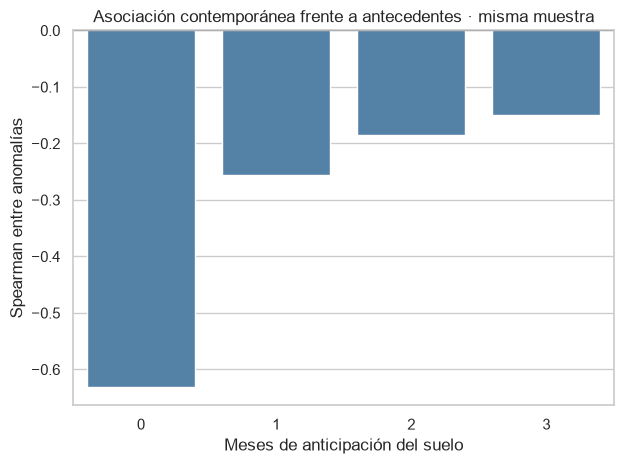

In [18]:
for k in range(4):
    for origen,prefijo in [(S_N,'suelo'),('anom_suelo','anom_suelo'),('resid_suelo','resid_suelo')]:
        datos_n[f'{prefijo}_lag{k}']=datos_n[origen].shift(k)
comun_n=datos_n.dropna(subset=[f'suelo_lag{k}' for k in range(4)])
rezagos_n=[]
for etiqueta,base in [('disponible',datos_n),('común a 0–3 meses',comun_n)]:
    for k in range(4):
        t=base.dropna(subset=[f'suelo_lag{k}'])
        rezagos_n.append({'muestra':etiqueta,'rezago_meses':k,'n':len(t),
          'rho_original':t[f'suelo_lag{k}'].corr(t[I_N],method='spearman'),
          'rho_anomalias':t[f'anom_suelo_lag{k}'].corr(t.anom_incendios,method='spearman'),
          'rho_sin_ciclo_tendencia':t[f'resid_suelo_lag{k}'].corr(t.resid_incendios,method='spearman')})
rezagos_n=pd.DataFrame(rezagos_n)
display(rezagos_n)
sns.barplot(data=rezagos_n[rezagos_n.muestra.eq('común a 0–3 meses')],x='rezago_meses',y='rho_anomalias',color='steelblue')
plt.axhline(0,color='black',lw=.8);plt.ylabel('Spearman entre anomalías');plt.xlabel('Meses de anticipación del suelo')
plt.title('Asociación contemporánea frente a antecedentes · misma muestra')
plt.tight_layout();plt.show()

## 10.5. ¿Depende la asociación contemporánea de un año excepcional?
Se omite un año calendario a la vez y se vuelven a calcular las medias mensuales y los residuos. Son diagnósticos de estabilidad, no intervalos de confianza ni pruebas causales. También se muestran episodios de suelo particularmente bajo para su mes, junto con conteos reales y sus anomalías. No se escogen como demostración de un mecanismo.

In [19]:
loo_n=[]
for anio in sorted(datos_n.anio_n.unique()):
    t=datos_n[datos_n.anio_n.ne(anio)].copy()
    s=t[S_N]-t.groupby('mes_n')[S_N].transform('mean')
    inc=t[I_N]-t.groupby('mes_n')[I_N].transform('mean')
    loo_n.append({'anio_omitido':int(anio),'n':len(t),'rho_anomalias':s.corr(inc,method='spearman'),
      'rho_sin_ciclo_tendencia':residuo_n(t[S_N],t).corr(residuo_n(t[I_N],t),method='spearman')})
loo_n=pd.DataFrame(loo_n)
display(loo_n)
print('Meses con las mayores anomalías negativas de suelo:')
display(datos_n.nsmallest(12,'anom_suelo')[['month',S_N,'anom_suelo',I_N,'anom_incendios','precipitation_mm','relative_humidity_2m_pct']])

,anio_omitido,n,rho_anomalias,rho_sin_ciclo_tendencia
0,2014,108,-0.6295,-0.6092
1,2015,102,-0.6718,-0.6357
2,2016,102,-0.6963,-0.6267
3,2017,102,-0.5910,-0.5607
4,2018,102,-0.5924,-0.5677
5,2019,102,-0.6137,-0.5868
6,2020,102,-0.6340,-0.5926
7,2021,102,-0.5654,-0.5500
8,2022,102,-0.6226,-0.5363
9,2023,102,-0.6024,-0.5797


Meses con las mayores anomalías negativas de suelo:


,month,soil_moisture_0_10cm_kgm2,anom_suelo,cantidad_incendios,anom_incendios,precipitation_mm,relative_humidity_2m_pct
23,2016-06,27.3890,-3.8351,1.0000,0.3333,42.4060,82.3940
88,2021-11,24.1080,-3.6576,161.0000,76.6000,13.3440,69.8400
69,2020-04,17.8520,-3.4879,218.0000,123.3333,54.8230,69.5250
89,2021-12,19.0260,-3.4555,286.0000,119.0000,6.9710,56.4940
57,2019-04,18.4840,-2.8559,149.0000,54.3333,38.3240,69.9210
8,2015-03,13.6920,-2.7133,361.0000,57.8889,8.2300,60.7310
9,2015-04,18.6630,-2.6769,28.0000,-66.6667,67.1110,77.4320
103,2023-02,13.2340,-2.4437,459.0000,106.7778,5.1990,50.9650
102,2023-01,15.8440,-2.4057,489.0000,184.3333,8.6510,55.5760
87,2021-10,28.3810,-2.3836,57.0000,24.8000,39.7280,74.9540


## 10.6. Prueba temporal experimental: ¿aporta el suelo del mes anterior?
**Objetivo:** evaluar información predictiva adicional; no explicar intencionalidad ni demostrar causalidad.

Se fijan los años de prueba **2019–2023**, con entrenamiento expansivo que termina en diciembre del año anterior. Se generan 60 predicciones mensuales fuera de muestra, con parámetros fijos durante cada año. El modelo de suelo utiliza su valor **del mes anterior**: se interpreta como horizonte de un mes y supone que ese agregado está disponible al emitir cada predicción; no se verificó la latencia operacional del producto NASA. No son doce pronósticos emitidos simultáneamente en enero.

Tres referencias, usando exactamente los mismos meses de entrenamiento y prueba:

1. Media histórica de incendios del mismo mes, calculada solo en entrenamiento.
2. Modelo de conteo con enlace log, efectos mensuales y tendencia temporal.
3. El mismo modelo, más la anomalía del suelo del mes previo respecto de la climatología de antecedentes de entrenamiento, estandarizada solo con entrenamiento.

Los dos modelos con enlace log minimizan una pérdida Poisson con penalización L2 fija 0,1 (sin penalizar intercepto), sin buscar hiperparámetros ni rezagos en prueba. La penalización evita inestabilidad de meses con muchos ceros. La dispersión real puede exceder Poisson: se evalúan **predicciones puntuales**, no se publican intervalos Poisson ni significancia de coeficientes.

Los modelos y esta evaluación son exploratorios, elegidos tras observar análisis descriptivos del período. La separación temporal evita fugas al ajustar parámetros, pero no convierte estos años en una prueba confirmatoria completamente independiente de las decisiones del investigador.

In [20]:
# El rezago se construyó antes de separar años: enero usa el suelo observado en diciembre.
modelado_n=datos_n.dropna(subset=['suelo_lag1']).copy()
def predecir_n(entrenamiento,prueba,incluir_suelo):
    climatologia=entrenamiento.groupby('mes_n').suelo_lag1.mean()
    desviacion=entrenamiento.suelo_lag1-entrenamiento.mes_n.map(climatologia)
    escala=float(desviacion.std(ddof=0))
    assert escala>0
    def matriz(t):
        partes=[np.ones(len(t))]+[t.mes_n.eq(m).to_numpy(dtype=float) for m in range(2,13)]+[t.tiempo_n.to_numpy()/10]
        X=np.column_stack(partes)
        if incluir_suelo:
            # Climatología de suelo t−1 agrupada por el mes objetivo, solo entrenamiento.
            X=np.column_stack([X,((t.suelo_lag1-t.mes_n.map(climatologia))/escala).to_numpy()])
        assert np.isfinite(X).all()
        return X
    X=matriz(entrenamiento);Xp=matriz(prueba)
    y=entrenamiento[I_N].to_numpy()
    penalizacion=np.full(X.shape[1],.1);penalizacion[0]=0
    def objetivo(b):
        eta=X@b;mu=np.exp(eta)
        perdida=np.sum(mu-y*eta)+.5*np.sum(penalizacion*b*b)
        gradiente=X.T@(mu-y)+penalizacion*b
        return perdida,gradiente
    inicial=np.zeros(X.shape[1]);inicial[0]=np.log(y.mean())
    solucion=minimize(objetivo,inicial,jac=True,method='L-BFGS-B',bounds=[(-15,15)]*X.shape[1],options={'maxiter':2000,'ftol':1e-11,'gtol':1e-6})
    assert solucion.success,solucion.message
    return np.exp(Xp@solucion.x),solucion.x[-1] if incluir_suelo else np.nan
predicciones_n=[]
coeficientes_n=[]
for anio in range(2019,2024):
    tr=modelado_n[modelado_n.anio_n<anio]
    te=modelado_n[modelado_n.anio_n.eq(anio)]
    assert len(te)==12 and tr.fecha.max()<te.fecha.min()
    pred_media=te.mes_n.map(tr.groupby('mes_n')[I_N].mean()).to_numpy()
    for nombre,usar_suelo in [('Estación + tendencia',False),('Estación + tendencia + suelo previo',True)]:
        pred,b=predecir_n(tr,te,usar_suelo)
        coeficientes_n.append({'anio_prueba':anio,'modelo':nombre,'beta_suelo_entrenamiento':b,'n_entrenamiento':len(tr)})
        for fecha,real,estimado in zip(te.fecha,te[I_N],pred):
            predicciones_n.append({'fecha':fecha,'anio_prueba':anio,'modelo':nombre,'observado':real,'predicho':estimado})
    for fecha,real,estimado in zip(te.fecha,te[I_N],pred_media):
        predicciones_n.append({'fecha':fecha,'anio_prueba':anio,'modelo':'Media histórica del mes','observado':real,'predicho':estimado})
predicciones_n=pd.DataFrame(predicciones_n)
assert len(predicciones_n)==60*3
assert predicciones_n.predicho.ge(0).all()
def metricas_n(g):
    y=g.observado.to_numpy();mu=np.maximum(g.predicho.to_numpy(),1e-10)
    return pd.Series({'n':len(g),'MAE':np.abs(y-mu).mean(),'RMSE':np.sqrt(np.mean((y-mu)**2)),
      'desviacion_Poisson_media':2*np.mean(xlogy(y,y/mu)-y+mu),'sesgo_pred_menos_real':np.mean(mu-y)})
metricas_total_n=predicciones_n.groupby('modelo').apply(metricas_n,include_groups=False)
metricas_anual_n=predicciones_n.groupby(['anio_prueba','modelo']).apply(metricas_n,include_groups=False)
display(metricas_total_n)
display(metricas_anual_n)
display(pd.DataFrame(coeficientes_n))

,n,MAE,RMSE,desviacion_Poisson_media,sesgo_pred_menos_real
modelo,,,,,
Estación + tendencia,60.0000,49.3628,73.5683,40.9214,-18.3470
Estación + tendencia + suelo previo,60.0000,50.1145,76.6400,41.3485,-11.1008
Media histórica del mes,60.0000,39.9471,62.7541,31.3526,-24.3524


n     MAE    RMSE  \
anio_prueba modelo                                                        
2019        Estación + tendencia                12.0000 70.0848 91.7476   
            Estación + tendencia + suelo previo 12.0000 72.2838 95.1044   
            Media histórica del mes             12.0000 36.7000 54.1261   
2020        Estación + tendencia                12.0000 48.1193 69.9721   
            Estación + tendencia + suelo previo 12.0000 47.6260 63.9395   
            Media histórica del mes             12.0000 46.9944 68.4978   
2021        Estación + tendencia                12.0000 53.1074 74.6496   
            Estación + tendencia + suelo previo 12.0000 45.2356 73.2023   
            Media histórica del mes             12.0000 43.8948 63.3889   
2022        Estación + tendencia                12.0000 38.8446 69.4227   
            Estación + tendencia + suelo previo 12.0000 50.8449 89.0749   
            Media histórica del mes             12.0000 33.8244 53.9022   
2023        Estación + tendencia                12.0000 36.6579 57.9283   
            Estación + tendencia + suelo previo 12.0000 34.5820 54.2445   
            Media histórica del mes             12.0000 38.3218 71.7300   

                                                 desviacion_Poisson_media  \
anio_prueba modelo                                                          
2019        Estación + tendencia                                  94.5733   
            Estación + tendencia + suelo previo                  103.0071   
            Media histórica del mes                               45.2700   
2020        Estación + tendencia                                  48.1216   
            Estación + tendencia + suelo previo                   39.7701   
            Media histórica del mes                               46.9853   
2021        Estación + tendencia                                  25.6262   
            Estación + tendencia + suelo previo                   21.1641   
            Media histórica del mes                               29.1393   
2022        Estación + tendencia                                  20.9584   
            Estación + tendencia + suelo previo                   27.4672   
            Media histórica del mes                               15.0544   
2023        Estación + tendencia                                  15.3274   
            Estación + tendencia + suelo previo                   15.3338   
            Media histórica del mes                               20.3138   

                                                 sesgo_pred_menos_real  
anio_prueba modelo                                                      
2019        Estación + tendencia                              -70.0848  
            Estación + tendencia + suelo previo               -72.2838  
            Media histórica del mes                           -36.7000  
2020        Estación + tendencia                              -46.1312  
            Estación + tendencia + suelo previo               -14.4502  
            Media histórica del mes                           -44.6056  
2021        Estación + tendencia                                5.0309  
            Estación + tendencia + suelo previo                10.3976  
            Media histórica del mes                           -17.1448  
2022        Estación + tendencia                               28.3792  
            Estación + tendencia + suelo previo                27.3446  
            Media histórica del mes                             3.3065  
2023        Estación + tendencia                               -8.9290  
            Estación + tendencia + suelo previo                -6.5125  
            Media histórica del mes                           -26.6181

,anio_prueba,modelo,beta_suelo_entrenamiento,n_entrenamiento
0,2019,Estación + tendencia,NaN,53
1,2019,Estación + tendencia + suelo previo,0.0373,53
2,2020,Estación + tendencia,NaN,65
3,2020,Estación + tendencia + suelo previo,-0.1836,65
4,2021,Estación + tendencia,NaN,77
5,2021,Estación + tendencia + suelo previo,-0.1573,77
6,2022,Estación + tendencia,NaN,89
7,2022,Estación + tendencia + suelo previo,-0.1630,89
8,2023,Estación + tendencia,NaN,101
9,2023,Estación + tendencia + suelo previo,-0.1284,101


C:\Users\smarc\AppData\Local\Temp\ipykernel_28312\391828176.py:4: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  axs[0].plot(reales.index,reales,color='black',lw=2,label='Observado')


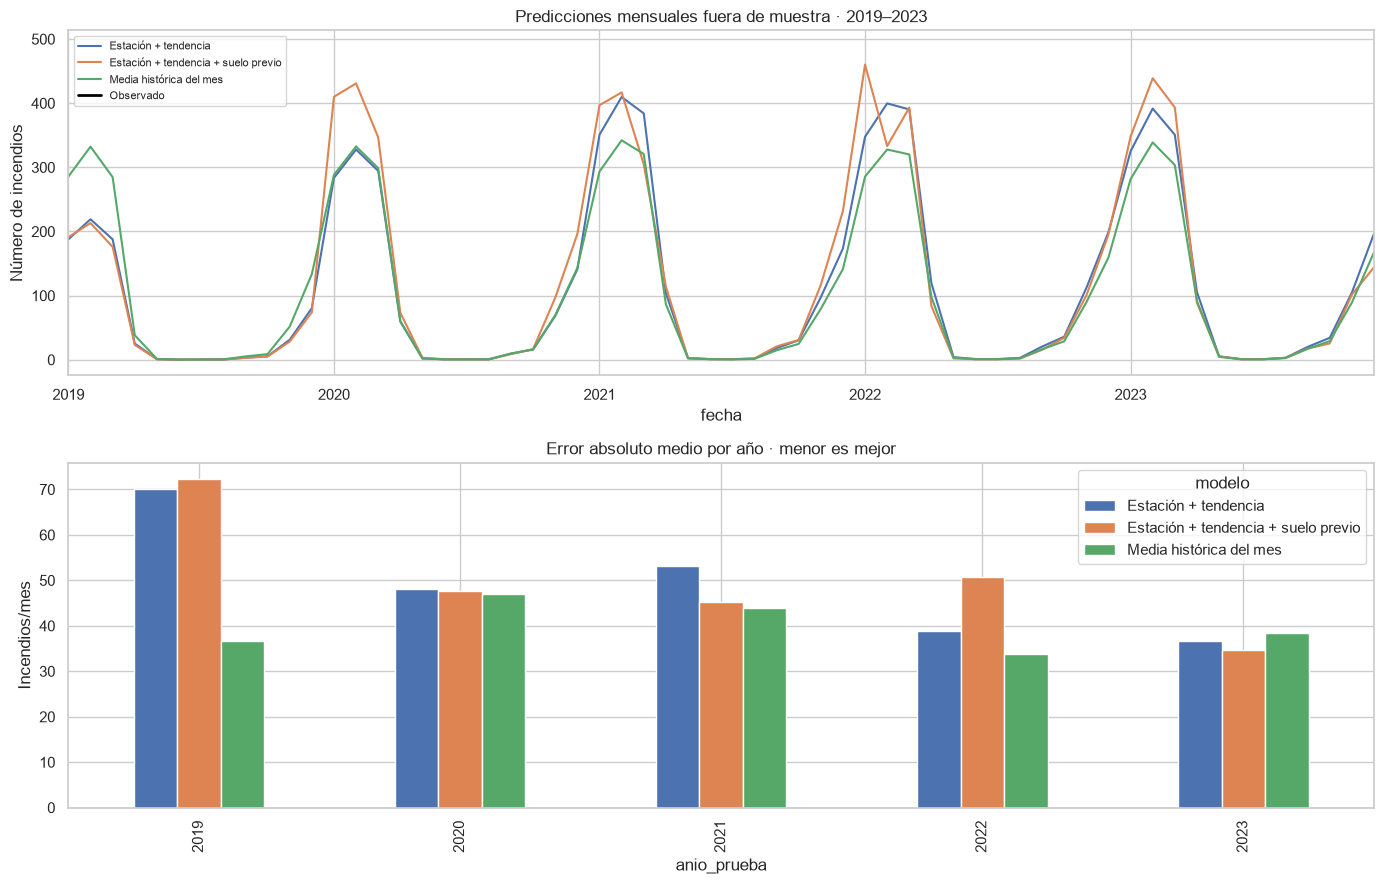

In [21]:
fig,axs=plt.subplots(2,1,figsize=(14,9))
predicciones_n.pivot(index='fecha',columns='modelo',values='predicho').plot(ax=axs[0])
reales=predicciones_n.drop_duplicates('fecha').set_index('fecha').observado
axs[0].plot(reales.index,reales,color='black',lw=2,label='Observado')
axs[0].set(title='Predicciones mensuales fuera de muestra · 2019–2023',ylabel='Número de incendios')
axs[0].legend(fontsize=8)
mae_anual_n=metricas_anual_n.MAE.unstack('modelo')
mae_anual_n.plot.bar(ax=axs[1])
axs[1].set(title='Error absoluto medio por año · menor es mejor',ylabel='Incendios/mes')
plt.tight_layout();plt.show()

## 10.7. Conclusiones del nuevo CSV: qué podemos sostener
La siguiente síntesis usa todos los resultados, incluidos los que no favorecen la utilidad predictiva del suelo. El hallazgo retrospectivo y el desempeño con antecedencia se presentan por separado.

In [22]:
r0=asociaciones_n.set_index('comparacion')
lag1=rezagos_n[(rezagos_n.muestra=='disponible')&(rezagos_n.rezago_meses==1)].iloc[0]
base=metricas_total_n.loc['Estación + tendencia']
suelo=metricas_total_n.loc['Estación + tendencia + suelo previo']
ingenua=metricas_total_n.loc['Media histórica del mes']
cambio_mae=100*(suelo.MAE/base.MAE-1)
cambio_rmse=100*(suelo.RMSE/base.RMSE-1)
mejores=int((mae_anual_n['Estación + tendencia + suelo previo']<mae_anual_n['Estación + tendencia']).sum())
calidos=resumen_grupos_n[resumen_grupos_n.ventana.eq('Noviembre–marzo')].set_index('grupo')
secos=calidos.loc['Seco','media_incendios_igual_peso_mes'];humedos=calidos.loc['Húmedo','media_incendios_igual_peso_mes']
texto=[
 '**Cobertura:** el nuevo CSV confirma 114 meses conjuntos; no aporta meses ambientales nuevos. Los seis de 2024 sin NASA se mantienen fuera del análisis conjunto.',
 f'**Asociación contemporánea:** Spearman original = {r0.loc["Original","spearman"]:.3f}; entre anomalías = {r0.loc["Anomalías de mes calendario","spearman"]:.3f}; sin ciclo ni tendencia lineal = {r0.loc["Residuos sin mes ni tendencia lineal","spearman"]:.3f}. Menos agua superficial del suelo coincide con más incendios registrados incluso después de esos ajustes descriptivos.',
 f'**Comparación dentro del calendario:** en noviembre–marzo, el tercio de suelo más seco presenta una media de {secos:.1f} incendios frente a {humedos:.1f} en el húmedo, dando igual peso a cada mes. No es un efecto causal estimado: quedan cambios en actividad humana, combustible, manejo y condiciones meteorológicas no controlados.',
 f'**Antecedencia:** usando suelo del mes anterior, Spearman entre anomalías = {lag1.rho_anomalias:.3f} (n={int(lag1.n)}). La tabla sobre 111 meses comunes permite contrastar rezagos sin cambiar fechas; una correlación contemporánea fuerte no se traslada automáticamente a capacidad de anticipación.',
 f'**Evaluación temporal:** en 60 meses de prueba, MAE de media histórica mensual = {ingenua.MAE:.2f}; estación+tendencia = {base.MAE:.2f}; añadiendo suelo previo = {suelo.MAE:.2f} incendios/mes. El cambio de MAE al agregar suelo es {cambio_mae:+.1f} % y el de RMSE es {cambio_rmse:+.1f} % (un aumento significa peor error). Mejora MAE en {mejores} de cinco años.']
if suelo.MAE>=base.MAE:
    texto.append('**Decisión:** el suelo es un descriptor ambiental relevante de los meses con incendios, pero este modelo y este horizonte no muestran mejora agregada al añadir suelo del mes anterior a estación+tendencia. No se justifica anunciar capacidad predictiva adicional demostrada. Esto no descarta otros modelos o escalas, pero deben evaluarse sin seleccionar resultados favorables sobre estos mismos años.')
else:
    texto.append('**Decisión:** el suelo previo mejora el MAE agregado en esta evaluación exploratoria; se debe contrastar la estabilidad anual y otras métricas antes de afirmar utilidad predictiva. No es evidencia causal ni una evaluación operacional independiente.')
texto.append('**Respecto de la intencionalidad:** estos datos no contienen causas ni intentos humanos de ignición. El resultado es compatible con condiciones ambientales que acompañan una mayor ocurrencia registrada, pero no identifica si hay más acciones humanas, mayor éxito de igniciones o diferencias de registro y control. Tampoco mide propagación o daño.')
display(Markdown((chr(10)*2).join(texto)))
assert hashlib.sha256(CSV_N.read_bytes()).hexdigest()==HASH_N
print('CSV original conservado sin cambios. Resultados agregados únicamente a analisis_suelo.ipynb.')

**Cobertura:** el nuevo CSV confirma 114 meses conjuntos; no aporta meses ambientales nuevos. Los seis de 2024 sin NASA se mantienen fuera del análisis conjunto.

**Asociación contemporánea:** Spearman original = -0.877; entre anomalías = -0.630; sin ciclo ni tendencia lineal = -0.593. Menos agua superficial del suelo coincide con más incendios registrados incluso después de esos ajustes descriptivos.

**Comparación dentro del calendario:** en noviembre–marzo, el tercio de suelo más seco presenta una media de 290.4 incendios frente a 176.2 en el húmedo, dando igual peso a cada mes. No es un efecto causal estimado: quedan cambios en actividad humana, combustible, manejo y condiciones meteorológicas no controlados.

**Antecedencia:** usando suelo del mes anterior, Spearman entre anomalías = -0.259 (n=113). La tabla sobre 111 meses comunes permite contrastar rezagos sin cambiar fechas; una correlación contemporánea fuerte no se traslada automáticamente a capacidad de anticipación.

**Evaluación temporal:** en 60 meses de prueba, MAE de media histórica mensual = 39.95; estación+tendencia = 49.36; añadiendo suelo previo = 50.11 incendios/mes. El cambio de MAE al agregar suelo es +1.5 % y el de RMSE es +4.2 % (un aumento significa peor error). Mejora MAE en 3 de cinco años.

**Decisión:** el suelo es un descriptor ambiental relevante de los meses con incendios, pero este modelo y este horizonte no muestran mejora agregada al añadir suelo del mes anterior a estación+tendencia. No se justifica anunciar capacidad predictiva adicional demostrada. Esto no descarta otros modelos o escalas, pero deben evaluarse sin seleccionar resultados favorables sobre estos mismos años.

**Respecto de la intencionalidad:** estos datos no contienen causas ni intentos humanos de ignición. El resultado es compatible con condiciones ambientales que acompañan una mayor ocurrencia registrada, pero no identifica si hay más acciones humanas, mayor éxito de igniciones o diferencias de registro y control. Tampoco mide propagación o daño.

CSV original conservado sin cambios. Resultados agregados únicamente a analisis_suelo.ipynb.
